# Cointegración y Modelo Vectorial de Corrección del Error (VECM)
## Guía de aprendizaje con aplicación a precios de petróleo crudo y gasóleo de calefacción

| Campo | Detalle |
|---|---|
| **Área** | Series de tiempo multivariadas · Econometría aplicada |
| **Nivel** | Maestría en Analítica de Datos |
| **Requisitos previos** | Estacionariedad, modelos ARIMA y nociones de VAR |
| **Herramientas** | Python 3, `pandas`, `numpy`, `statsmodels`, `scipy`, `matplotlib`, `seaborn` |
| **Datos** | Futuros NYMEX de petróleo crudo WTI (`CL=F`) y gasóleo de calefacción (`HO=F`), cierres diarios congelados en `datos_vecm.csv` |
| **Período de análisis** | Enero 2015 – diciembre 2024, frecuencia mensual (último cierre de cada mes) |
| **Versión** | 2 (noviembre de 2026) |

> **Cómo usar este cuaderno.** Ejecútelo de arriba hacia abajo. Cada procedimiento empieza con cuatro preguntas
> (qué problema resolvemos, por qué, qué calculamos y cómo leeremos el resultado) y termina con una interpretación de las
> salidas. Las **actividades** aparecen a lo largo del texto; sus **respuestas sugeridas** están reunidas al final, para
> que el cuaderno pueda usarse en clase. Las interpretaciones escritas se contrastaron con las salidas que produce el
> archivo de datos congelado: si cambia los datos, vuelva a leer las salidas antes de aceptar cualquier conclusión.

### Mapa del cuaderno

| Módulo | Tema | Pregunta que responde |
|---|---|---|
| 0 | Configuración | ¿Qué necesito para ejecutar el cuaderno? |
| 1 | Motivación económica | ¿Por qué esperar una relación de largo plazo entre crudo y gasóleo? |
| 2 | Series no estacionarias, regresión espuria y cointegración | ¿Por qué la correlación no basta? |
| 3 | Del VAR al VECM | ¿Cómo se pasa de un VAR a un modelo con corrección del error? |
| 4 | Datos reales | ¿Qué datos usamos y cómo se preparan? |
| 5 | Orden de integración | ¿Las series son I(1)? ¿Qué tan seguros estamos? |
| 6 | Rezagos y prueba de Johansen | ¿Cuántos rezagos, qué términos deterministas y cuántas relaciones de cointegración? |
| 7 | Estimación e interpretación | ¿Qué dicen β, α, Γ y el ECT? |
| 8 | Diagnóstico y validación | ¿El modelo está bien especificado? ¿Qué tan robusto es? |
| 9 | Respuestas a impulsos | ¿Qué ocurre tras un choque? |
| 10 | Pronóstico | ¿Pronostica mejor que alternativas simples? |
| 11 | Conclusiones y limitaciones | ¿Qué podemos concluir y qué no? |
| 12 | Actividades integradoras | Ejercicios progresivos y proyecto final |
| — | Respuestas sugeridas · Apéndices · Referencias | Material de apoyo |

---
## Módulo 0. Configuración del entorno

El cuaderno no necesita internet: el caso base lee `datos_vecm.csv`, que debe estar en la misma carpeta. La descarga
desde Yahoo Finance se conserva como opción (Módulo 4). Las dependencias están en `requirements.txt`.

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import scipy
from scipy import stats
import statsmodels
import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller, kpss, coint
from statsmodels.tsa.api import VAR
from statsmodels.tsa.vector_ar.vecm import VECM, select_order, coint_johansen
from statsmodels.stats.diagnostic import het_arch, acorr_ljungbox
from statsmodels.tools.sm_exceptions import InterpolationWarning
from IPython.display import display

# Solo se silencian avisos conocidos e inofensivos:
warnings.filterwarnings("ignore", category=InterpolationWarning)          # p-valor de KPSS fuera de tabla (se indica en la tabla)
warnings.filterwarnings("ignore", message=".*frequency information.*")    # aviso de fechas en modelos sin predicción
warnings.filterwarnings("ignore", category=np.exceptions.ComplexWarning)  # autovalores reales guardados como complejos

SEMILLA = 2024

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.figsize": (11, 4.2), "figure.dpi": 100, "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.labelsize": 10.5, "legend.frameon": False,
    "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 1.8,
})
# Colores fijos por entidad: la misma variable o el mismo modelo siempre llevan el mismo color.
COL = {"CL": "#2a78d6", "HO": "#eb6834", "ECT": "#6250d6",
       "VECM": "#2a78d6", "VAR_dif": "#eb6834", "VAR_niv": "#1baf7a", "Ingenuo": "#7a7974",
       "obs": "#222222", "ref": "#9a9994"}
ETIQ = {"ln_CL": "ln(crudo WTI)", "ln_HO": "ln(gasóleo)"}
# Nota: en los gráficos los subíndices y acentos matemáticos se escriben con la notación $...$ de matplotlib,
# porque algunas fuentes de Windows (p. ej. Arial) no incluyen caracteres como "₂".

def eje_fechas(ax, paso_anios=1):
    ax.xaxis.set_major_locator(mdates.YearLocator(paso_anios))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

print(f"Python      : {__import__('sys').version.split()[0]}")
for lib in (np, pd, scipy, statsmodels, matplotlib, sns):
    print(f"{lib.__name__:<12}: {lib.__version__}")

Python      : 3.13.18
numpy       : 2.5.3
pandas      : 2.3.3
scipy       : 1.18.1
statsmodels : 0.14.5
matplotlib  : 3.11.2
seaborn     : 0.13.2


> **Nota de versiones.** El cuaderno se verificó con `statsmodels` 0.14.5 y 0.14.6, `pandas` 2.3.3 y Python 3.13.
> Las funciones de `statsmodels` usadas existen con la misma firma en toda la serie 0.14.

---
## Módulo 1. Motivación económica: ¿por qué estudiar cointegración?

### 1.1 ¿Por qué estos dos precios deberían estar relacionados?

El gasóleo de calefacción (*heating oil*, hoy ULSD) se obtiene refinando petróleo crudo, de modo que el crudo es su
principal costo. La diferencia entre el valor de los productos refinados y el del crudo —el **margen de refinación** o
*crack spread*— remunera a las refinerías. Si el margen se vuelve inusualmente alto, conviene procesar más crudo: eso
presiona al alza la demanda de crudo y a la baja el precio del gasóleo. Si se vuelve muy bajo, ocurre lo contrario.
Los operadores de futuros, además, toman posiciones cuando el diferencial se aleja de lo habitual.

El argumento no dice que los precios se muevan igual cada mes —el gasóleo tiene choques propios: inviernos fríos,
inventarios de destilados, paradas de refinerías—, sino que **no pueden alejarse indefinidamente uno del otro**.

### 1.2 Largo plazo frente a corto plazo

- **Corto plazo:** variaciones mes a mes, ruidosas, con choques específicos de cada mercado.
- **Largo plazo:** una relación de equilibrio, por ejemplo $\ln CL_t \approx \mu + b\,\ln HO_t$, alrededor de la cual los
  precios fluctúan. El **desequilibrio** $\ln CL_t - \mu - b\ln HO_t$ debería ser transitorio.

"Equilibrio" no significa precios quietos: significa que existe una combinación de ellos que no se aleja
sistemáticamente de un valor central. Esa es exactamente la idea de cointegración.

### 1.3 Preguntas que guían el análisis

1. ¿Existe evidencia estadística de una relación estable de largo plazo?
2. Si existe, ¿cuál es su forma y qué precio corrige los desequilibrios?
3. ¿Cómo se propaga un choque de un mercado al otro?
4. ¿Ayuda esa estructura a pronosticar mejor que alternativas simples?
5. ¿Qué tan sensibles son las respuestas a las decisiones del analista?

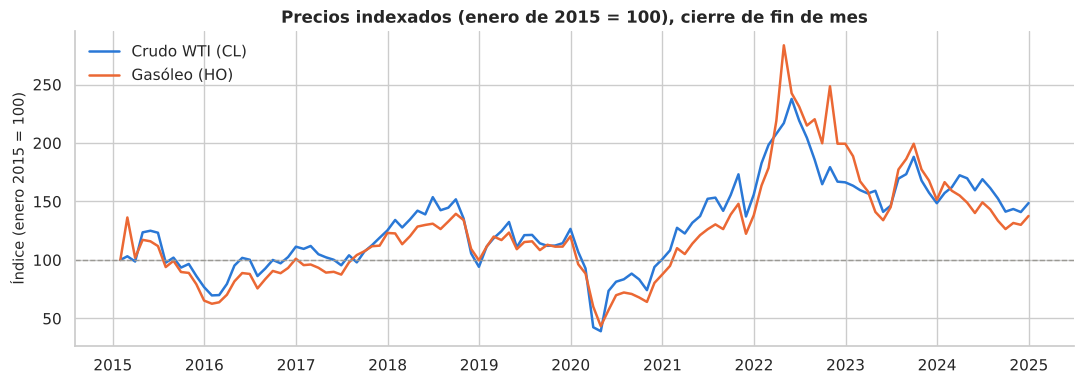

In [2]:
RUTA_DATOS = Path("datos_vecm.csv")
if not RUTA_DATOS.exists():
    raise FileNotFoundError("No se encuentra 'datos_vecm.csv'. Debe estar en la misma carpeta que este cuaderno.")

vista = pd.read_csv(RUTA_DATOS, parse_dates=["fecha"], index_col="fecha").dropna().resample("ME").last()

fig, ax = plt.subplots(figsize=(11, 4))
indice = 100 * vista / vista.iloc[0]
ax.plot(indice.index, indice.iloc[:, 0], color=COL["CL"], label="Crudo WTI (CL)")
ax.plot(indice.index, indice.iloc[:, 1], color=COL["HO"], label="Gasóleo (HO)")
ax.axhline(100, color=COL["ref"], lw=1, ls="--")
ax.set_title("Precios indexados (enero de 2015 = 100), cierre de fin de mes")
ax.set_ylabel("Índice (enero 2015 = 100)"); ax.legend(loc="upper left")
eje_fechas(ax)
plt.tight_layout(); plt.show()

**Lectura del gráfico.** Al indexar ambas series a 100 las comparamos en un mismo eje, sin recurrir a dos escalas
verticales (un gráfico de doble eje permite "ajustar" visualmente casi cualquier par de series). Las trayectorias suben y
bajan juntas: caída de 2015-2016, colapso de 2020 y alza de 2022. **Esto no prueba nada**: dos series con tendencia casi
siempre parecen relacionadas. El Módulo 2 muestra por qué la impresión visual no basta y los Módulos 5-6 la someten a
pruebas formales.

> **Actividad 1.1.** ¿Qué esperaría ver en el gráfico indexado si el margen de refinación se ampliara de forma
> permanente a partir de cierto año? ¿Seguiría habiendo cointegración en toda la muestra?

---
## Módulo 2. Series no estacionarias, regresión espuria y cointegración

**Objetivo de aprendizaje:** entender con ejemplos controlados qué es una serie $I(1)$, por qué la regresión entre series
$I(1)$ puede ser espuria y qué cambia cuando existe una combinación lineal estacionaria.

### 2.1 Ejemplo numérico: ¿qué significa que una serie sea I(1)?

Un **paseo aleatorio** acumula choques: $x_t = x_{t-1} + e_t$. Suponga $x_0 = 10$ y los choques $e = (0.5,\,-0.3,\,0.8,\,0.2,\,-0.6)$:

| $t$ | 0 | 1 | 2 | 3 | 4 | 5 |
|---|---|---|---|---|---|---|
| $e_t$ | — | 0.5 | −0.3 | 0.8 | 0.2 | −0.6 |
| $x_t$ | 10.0 | 10.5 | 10.2 | 11.0 | 11.2 | 10.6 |
| $\Delta x_t$ | — | 0.5 | −0.3 | 0.8 | 0.2 | −0.6 |

El choque de 0.5 del período 1 **sigue presente** en $x_5$: nada lo devuelve a 10. Por eso $x_t$ no tiene una media a la
que regresar (no es estacionaria), pero su primera diferencia $\Delta x_t = e_t$ sí lo es. Eso es una serie **integrada de
orden 1**, $I(1)$: hay que diferenciarla una vez para obtener una serie estacionaria, $I(0)$.

Compárese con un proceso estacionario $z_t = 0.5\,z_{t-1} + e_t$ con los mismos choques y $z_0=0$: $z = (0,\ 0.5,\ -0.05,\ 0.78,\ 0.59,\ -0.31)$.
Cada choque se diluye a la mitad en el período siguiente y la serie vuelve hacia cero.

### 2.2 Cointegración: una combinación lineal estacionaria

Dos series $I(1)$, $y_t$ y $x_t$, están **cointegradas** si existe un $b$ tal que

$$u_t = y_t - a - b\,x_t \quad \text{es estacionaria, } I(0).$$

Ejemplo: si $x_t$ es el paseo aleatorio anterior y $y_t = 2 + 0.8\,x_t + u_t$ con $u_t$ estacionario, entonces $y_t$
"hereda" la tendencia estocástica de $x_t$. Si en $t=3$ tenemos $x_3 = 11.0$ y observamos $y_3 = 11.1$, el desequilibrio es
$u_3 = 11.1 - 2 - 0.8\times 11.0 = 0.30$: $y$ está 0.30 por encima de su valor de equilibrio (10.8). Como $u_t$ es
estacionario, esa brecha tiende a cerrarse. Ambas series se mueven por la **misma** tendencia estocástica, y la
combinación $y_t - 0.8x_t$ la cancela.

Simulamos dos casos con $T = 300$ y semilla fija:

- **Caso A (cointegrado):** $x_t$ paseo aleatorio y $y_t = 2 + 0.8\,x_t + u_t$, con $u_t = 0.6\,u_{t-1} + \eta_t$.
- **Caso B (no cointegrado):** dos paseos aleatorios **independientes**, ambos con deriva positiva.

Correlación en niveles, caso A (cointegrado):     0.942
Correlación en niveles, caso B (independientes):  0.947


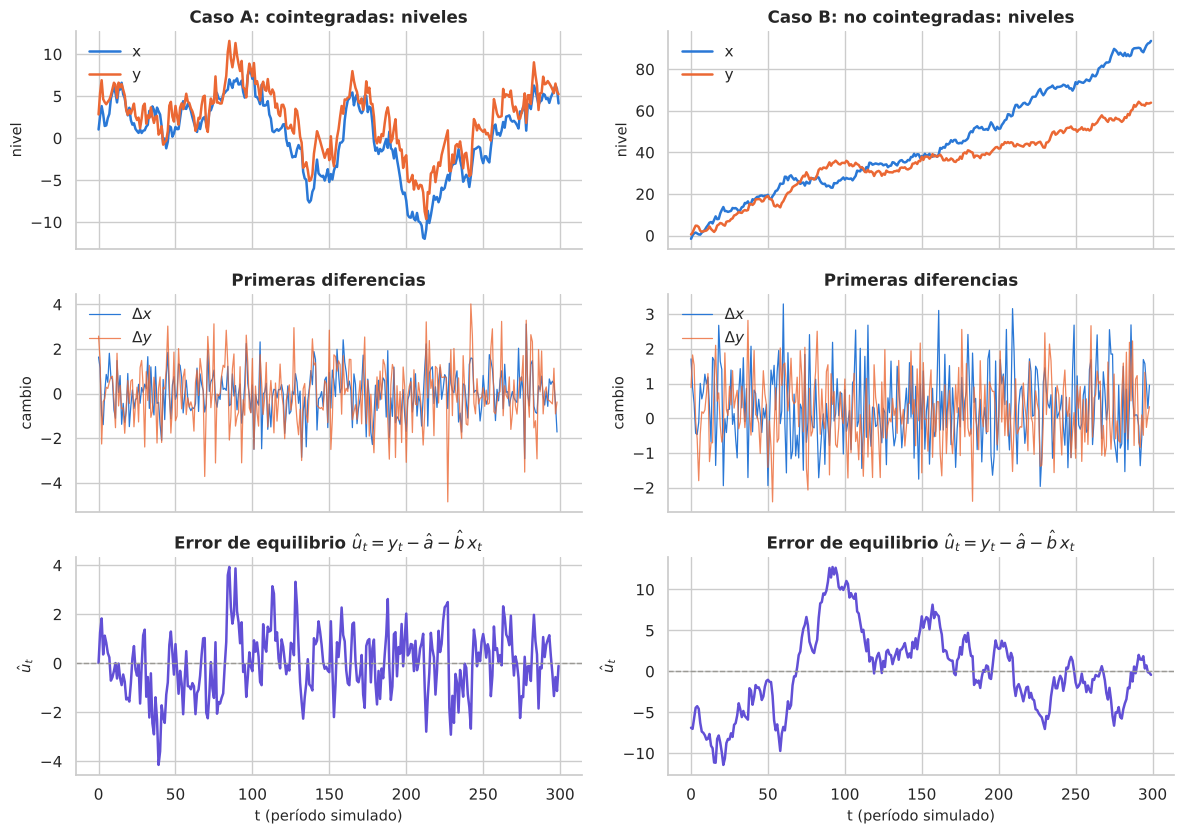

Caso A: b̂ = 0.811 | Engle-Granger: estadístico = -8.47, p-valor = 0.0000
Caso B: b̂ = 0.598 | Engle-Granger: estadístico = -2.15, p-valor = 0.4520


In [3]:
rng_sim = np.random.default_rng(SEMILLA)   # semilla propia: el módulo es reproducible por sí solo
T_SIM = 300

# Caso A: cointegración
x_A = np.cumsum(rng_sim.normal(0, 1, T_SIM))
u_A = np.zeros(T_SIM)
for t in range(1, T_SIM):
    u_A[t] = 0.6 * u_A[t - 1] + rng_sim.normal(0, 1)
y_A = 2 + 0.8 * x_A + u_A

# Caso B: paseos aleatorios independientes con deriva
x_B = np.cumsum(0.30 + rng_sim.normal(0, 1, T_SIM))
y_B = np.cumsum(0.25 + rng_sim.normal(0, 1, T_SIM))

print(f"Correlación en niveles, caso A (cointegrado):     {np.corrcoef(x_A, y_A)[0, 1]:.3f}")
print(f"Correlación en niveles, caso B (independientes):  {np.corrcoef(x_B, y_B)[0, 1]:.3f}")

def ecuacion_equilibrio(y, x):
    # Regresión estática y = a + b x por MCO; devuelve (a, b, residuo)
    X = np.column_stack([np.ones_like(x), x])
    a, b = np.linalg.lstsq(X, y, rcond=None)[0]
    return a, b, y - a - b * x

aA, bA, resA = ecuacion_equilibrio(y_A, x_A)
aB, bB, resB = ecuacion_equilibrio(y_B, x_B)

fig, axes = plt.subplots(3, 2, figsize=(12, 8.5), sharex=True)
for j, (xs, ys, res, titulo) in enumerate([(x_A, y_A, resA, "Caso A: cointegradas"),
                                           (x_B, y_B, resB, "Caso B: no cointegradas")]):
    axes[0, j].plot(xs, color=COL["CL"], label="x"); axes[0, j].plot(ys, color=COL["HO"], label="y")
    axes[0, j].set_title(f"{titulo}: niveles"); axes[0, j].legend(loc="upper left"); axes[0, j].set_ylabel("nivel")
    axes[1, j].plot(np.diff(xs), color=COL["CL"], lw=0.9, label=r"$\Delta x$")
    axes[1, j].plot(np.diff(ys), color=COL["HO"], lw=0.9, alpha=0.8, label=r"$\Delta y$")
    axes[1, j].set_title("Primeras diferencias"); axes[1, j].legend(loc="upper left"); axes[1, j].set_ylabel("cambio")
    axes[2, j].plot(res, color=COL["ECT"])
    axes[2, j].axhline(0, color=COL["ref"], ls="--", lw=1)
    axes[2, j].set_title(r"Error de equilibrio $\hat u_t = y_t - \hat a - \hat b\,x_t$")
    axes[2, j].set_xlabel("t (período simulado)"); axes[2, j].set_ylabel(r"$\hat u_t$")
plt.tight_layout(); plt.show()

# Engle-Granger: valores críticos propios, porque el residuo proviene de una regresión estimada
for caso, (ys, xs, b) in {"A": (y_A, x_A, bA), "B": (y_B, x_B, bB)}.items():
    est, p, _ = coint(ys, xs, trend="c")
    print(f"Caso {caso}: b̂ = {b:.3f} | Engle-Granger: estadístico = {est:.2f}, p-valor = {p:.4f}")

**Interpretación.**

- En ambos casos los niveles deambulan sin volver a un valor fijo y las diferencias oscilan alrededor de cero: las
  cuatro series se comportan como $I(1)$.
- **Caso A:** el error de equilibrio cruza el cero una y otra vez; la pendiente estimada queda cerca del 0.8 verdadero y la
  prueba de Engle-Granger rechaza la hipótesis nula de *no cointegración*.
- **Caso B:** la correlación en niveles es tan alta como en el caso A (incluso algo mayor), pero el "error de equilibrio"
  tiene rachas largas lejos de cero y la prueba no rechaza la nula. La alta correlación se debe solo a que ambas series
  tienen deriva positiva.

### 2.3 La regresión espuria

¿Qué pasa si, ignorando lo anterior, estimamos por MCO la regresión del caso B y leemos el estadístico $t$ como de
costumbre? Granger y Newbold (1974) mostraron que, con series $I(1)$ independientes, la regresión en niveles produce
$R^2$ altos y estadísticos $t$ "significativos" con mucha más frecuencia que el 5 % nominal. Lo comprobamos con el caso B
y con una pequeña simulación de Monte Carlo.

Caso B en niveles:     pendiente = 0.598, t = 51.1, R² = 0.897
Caso B en diferencias: pendiente = 0.097, t = 1.79, R² = 0.011



Frecuencia de |t| > 1.96 con series independientes: niveles 86.4%, diferencias 5.7%  (nominal: 5%)


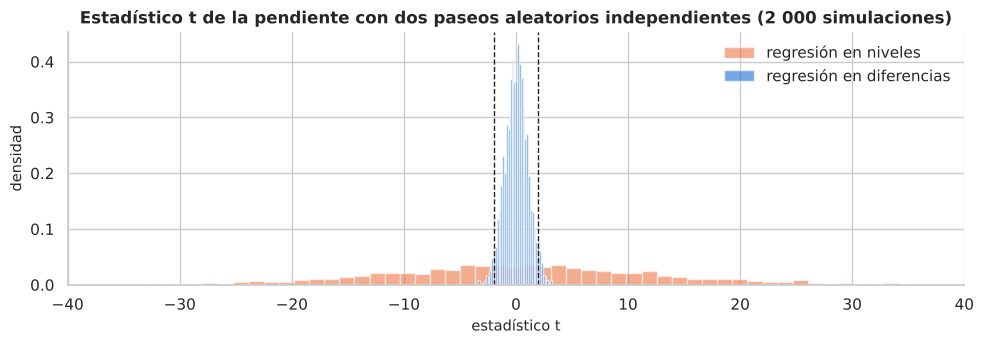

In [4]:
reg_B = sm.OLS(y_B, sm.add_constant(x_B)).fit()
reg_B_dif = sm.OLS(np.diff(y_B), sm.add_constant(np.diff(x_B))).fit()
print(f"Caso B en niveles:     pendiente = {reg_B.params[1]:.3f}, t = {reg_B.tvalues[1]:.1f}, R² = {reg_B.rsquared:.3f}")
print(f"Caso B en diferencias: pendiente = {reg_B_dif.params[1]:.3f}, t = {reg_B_dif.tvalues[1]:.2f}, R² = {reg_B_dif.rsquared:.3f}")

# Monte Carlo: dos paseos aleatorios independientes SIN deriva, T = 300
rng_mc = np.random.default_rng(SEMILLA + 7)
REPS = 2000
t_niv, t_dif = np.empty(REPS), np.empty(REPS)
for i in range(REPS):
    a = np.cumsum(rng_mc.standard_normal(T_SIM)); b = np.cumsum(rng_mc.standard_normal(T_SIM))
    t_niv[i] = sm.OLS(a, sm.add_constant(b)).fit().tvalues[1]
    t_dif[i] = sm.OLS(np.diff(a), sm.add_constant(np.diff(b))).fit().tvalues[1]
print(f"\nFrecuencia de |t| > 1.96 con series independientes: niveles {np.mean(np.abs(t_niv) > 1.96):.1%}, "
      f"diferencias {np.mean(np.abs(t_dif) > 1.96):.1%}  (nominal: 5%)")

fig, ax = plt.subplots(figsize=(10, 3.6))
ax.hist(t_niv, bins=80, density=True, color=COL["HO"], alpha=0.55, label="regresión en niveles")
ax.hist(t_dif, bins=40, density=True, color=COL["CL"], alpha=0.65, label="regresión en diferencias")
for v in (-1.96, 1.96):
    ax.axvline(v, color=COL["obs"], ls="--", lw=1)
ax.set_xlim(-40, 40)
ax.set_title("Estadístico t de la pendiente con dos paseos aleatorios independientes (2 000 simulaciones)")
ax.set_xlabel("estadístico t"); ax.set_ylabel("densidad"); ax.legend()
plt.tight_layout(); plt.show()

**Interpretación.** En el caso B la regresión en niveles da una pendiente con un estadístico $t$ enorme y un $R^2$ alto,
aunque las series son independientes por construcción; en diferencias, la relación desaparece. La simulación generaliza
el resultado: con series $I(1)$ independientes, la regresión en niveles "encuentra" una relación significativa en la
gran mayoría de los casos, mientras que en diferencias el rechazo vuelve a rondar el 5 %. La distribución del $t$ en
niveles es muchísimo más ancha que una normal: los valores críticos habituales no sirven.

**Mensaje clave.** Con series $I(1)$ hay tres situaciones: (i) no cointegradas → la regresión en niveles es espuria y hay
que trabajar en diferencias; (ii) cointegradas → existe una relación de largo plazo genuina, pero modelar solo en
diferencias pierde información; (iii) por eso necesitamos **probar** la cointegración antes de elegir el modelo.

> **Error frecuente.** Aplicar un ADF ordinario al residuo de la regresión estática y usar sus valores críticos. Como
> $\hat b$ minimiza la varianza del residuo, este parece "más estacionario" de lo que es; la prueba de Engle-Granger
> (`coint`) usa valores críticos más exigentes.

> **Actividad 2.1.** Cambie el 0.6 del caso A por 0.98 y vuelva a ejecutar. ¿Qué le pasa al error de equilibrio y al
> p-valor de Engle-Granger? ¿Siguen estando cointegradas las series en sentido teórico?
>
> **Actividad 2.2.** ¿Por qué en la regresión espuria el $R^2$ suele ser alto aunque no exista relación? Responda
> pensando en qué ocurre con la varianza muestral de un paseo aleatorio cuando $T$ crece.

---
## Módulo 3. Del VAR al VECM

**Objetivo de aprendizaje:** entender que un VECM es un VAR en niveles reorganizado, y qué significan $\Pi$, $\alpha$,
$\beta$, $\Gamma$, el ECT y los términos deterministas.

### 3.1 Punto de partida: un VAR($p$)

Con $k$ variables, un VAR($p$) escribe cada variable como función de sus rezagos y de los rezagos de las demás:

$$\mathbf{y}_t = \mathbf{c} + \mathbf{A}_1\mathbf{y}_{t-1} + \cdots + \mathbf{A}_p\mathbf{y}_{t-p} + \boldsymbol{\varepsilon}_t,
\qquad \boldsymbol{\varepsilon}_t \sim (\mathbf{0}, \boldsymbol{\Sigma}),$$

donde $\mathbf{y}_t$ es $k\times 1$ (aquí $\mathbf y_t = (\ln CL_t,\ \ln HO_t)'$), cada $\mathbf{A}_i$ es $k\times k$ y
$\boldsymbol\Sigma$ es la matriz de covarianzas de los errores.

Con series $I(1)$, un **VAR en niveles** puede estimarse, pero la inferencia estándar no es válida en general y no
separa el corto del largo plazo. Un **VAR en diferencias** es estacionario, pero al diferenciar se pierde la información
sobre los niveles: si las series están cointegradas, omite una variable relevante, la distancia al equilibrio.

### 3.2 Caso bivariado con un rezago

Con $p=1$, restamos $\mathbf y_{t-1}$ a ambos lados de $\mathbf{y}_t = \mathbf{c} + \mathbf{A}_1 \mathbf{y}_{t-1} + \boldsymbol\varepsilon_t$:

$$\Delta\mathbf{y}_t = \mathbf{c} + \underbrace{(\mathbf{A}_1 - \mathbf{I})}_{\boldsymbol\Pi}\,\mathbf{y}_{t-1} + \boldsymbol\varepsilon_t .$$

Si hay una relación de cointegración ($r=1$), $\boldsymbol\Pi$ tiene rango 1 y se factoriza como $\boldsymbol\Pi = \boldsymbol\alpha\boldsymbol\beta'$:

$$\begin{pmatrix}\Delta y_{1t}\\ \Delta y_{2t}\end{pmatrix}
= \begin{pmatrix}c_1\\ c_2\end{pmatrix}
+ \begin{pmatrix}\alpha_1\\ \alpha_2\end{pmatrix}
\underbrace{\big(\beta_1 y_{1,t-1} + \beta_2 y_{2,t-1}\big)}_{\text{desequilibrio en } t-1}
+ \begin{pmatrix}\varepsilon_{1t}\\ \varepsilon_{2t}\end{pmatrix}.$$

Cada variable cambia hoy en respuesta a **qué tan lejos estuvo el sistema del equilibrio el período anterior**.

### 3.3 Forma general y relación con los rezagos

Para un VAR($p$) la reorganización (derivada en el **Apéndice A**) da

$$\Delta\mathbf{y}_t = \mathbf{c} + \boldsymbol\alpha\boldsymbol\beta'\mathbf{y}_{t-1}
+ \sum_{i=1}^{p-1}\boldsymbol\Gamma_i\,\Delta\mathbf{y}_{t-i} + \boldsymbol\varepsilon_t .$$

| Símbolo | Dimensión | Significado | En `statsmodels` |
|---|---|---|---|
| $\boldsymbol\beta$ | $k\times r$ | Vectores de cointegración: $\boldsymbol\beta'\mathbf{y}_t$ es estacionario (largo plazo) | `res.beta` |
| $\boldsymbol\alpha$ | $k\times r$ | Coeficientes de ajuste: cómo responde cada ecuación al desequilibrio | `res.alpha` |
| $\boldsymbol\Pi=\boldsymbol\alpha\boldsymbol\beta'$ | $k\times k$ | Efecto de los niveles rezagados; su rango es $r$ | `res.alpha @ res.beta.T` |
| $\boldsymbol\Gamma_i$ | $k\times k$ | Dinámica de corto plazo: efecto de los cambios pasados | `res.gamma` |
| $r$ | escalar | Rango de cointegración: número de relaciones de equilibrio | argumento `coint_rank` |
| $p-1$ | escalar | Rezagos en diferencias | argumento `k_ar_diff` |

**Rezagos.** Un VECM con `k_ar_diff` $=p-1$ es **el mismo modelo** que un VAR($p$) en niveles con la restricción de rango
sobre $\boldsymbol\Pi$. Un VECM con `k_ar_diff = 0` (sin $\Gamma$) corresponde a un VAR(1) en niveles y es perfectamente válido.

| Rango de $\boldsymbol\Pi$ | Implicación | Modelo natural |
|---|---|---|
| $r = 0$ | No hay cointegración; $\boldsymbol\Pi = \mathbf 0$ | VAR en primeras diferencias |
| $0 < r < k$ | $r$ relaciones de equilibrio y $k-r$ tendencias estocásticas comunes | **VECM** |
| $r = k$ | $\boldsymbol\Pi$ de rango completo: todas las series son estacionarias | VAR en niveles |

### 3.4 Normalización, signo de $\alpha$ y exogeneidad débil

1. **La factorización no es única.** Para cualquier $c\neq 0$, $\boldsymbol\alpha\boldsymbol\beta' = (\boldsymbol\alpha c)(\boldsymbol\beta/c)'$.
   Por eso se **normaliza** $\beta$ (aquí, primer elemento igual a 1). La normalización es una convención matemática, no
   una afirmación causal ni una identificación económica de la relación.
2. **El signo de $\alpha$ depende de la normalización.** Con $ECT = y_1 - b\,y_2$ y $b>0$, la variable 1 corrige si
   $\alpha_1<0$, y la variable 2 corrige si $\alpha_2>0$ (cuando $ECT>0$, $y_1$ está "alto" relativo a $y_2$, y que $y_2$
   suba también cierra la brecha). **Un $\alpha$ positivo no es, por sí solo, una señal de error.**
3. **Exogeneidad débil.** Si $\alpha_i = 0$, la variable $i$ no reacciona al desequilibrio: el ajuste lo hacen las demás.
   Se dice que la variable $i$ es *débilmente exógena* respecto a $\beta$. Es una hipótesis que se contrasta (Módulo 7).

### 3.5 Términos deterministas: constante dentro o fuera de la relación

La constante puede entrar de dos maneras, y la elección cambia la interpretación:

- **Constante sin restringir** (`deterministic="co"`): $\Delta\mathbf y_t = \mathbf c + \boldsymbol\alpha\boldsymbol\beta'\mathbf y_{t-1} + \dots$
  El vector $\mathbf c$ de cada ecuación mezcla dos cosas: la media del equilibrio y una posible **deriva** (tendencia lineal)
  en los niveles. La relación $\boldsymbol\beta'\mathbf y_t$ no tiene constante propia, así que su media no es cero.
- **Constante restringida** (`deterministic="ci"`): $\Delta\mathbf y_t = \boldsymbol\alpha(\boldsymbol\beta'\mathbf y_{t-1} + \mu_0) + \dots$
  La constante $\mu_0$ vive **dentro** de la relación de equilibrio. Los niveles no tienen deriva y el término de
  corrección del error $ECT_t = \boldsymbol\beta'\mathbf y_t + \mu_0$ se mide en torno a cero.

Si en el modelo `"co"` se cumple $\mathbf c = \boldsymbol\alpha\mu_0$, ambos son equivalentes: esa es una restricción
contrastable (Módulo 7). Lo que **no** es válido es estimar con `"co"` y tomar $\mu_0$ de un modelo `"ci"` distinto:
serían parámetros de especificaciones diferentes.

### 3.6 Ejemplo numérico: cuánto se corrige realmente

Suponga $\boldsymbol\beta = (1,\,-1)'$, $\boldsymbol\alpha = (-0.25,\ 0.10)'$, sin $\Gamma$, sin constantes ni choques, y un
desequilibrio inicial $ECT_{t-1} = y_{1,t-1} - y_{2,t-1} = 0.10$:

- $\Delta y_{1t} = -0.25\times 0.10 = -0.025$ (la variable 1 baja: **un $\alpha_1$ negativo significa que la variable que
  está "arriba" en la relación baja cuando el desequilibrio es positivo**)
- $\Delta y_{2t} = \ \ 0.10\times 0.10 = \ \ 0.010$ (la variable 2 sube)
- Nuevo desequilibrio: $ECT_t = ECT_{t-1} + \Delta y_{1t} - \Delta y_{2t} = 0.10 - 0.025 - 0.010 = 0.065$.

Se corrigió el 35 % de la brecha, no el 25 % que sugeriría mirar solo $\alpha_1$. Sin $\Gamma$, el desequilibrio sigue
$ECT_t = (1 + \boldsymbol\beta'\boldsymbol\alpha)\,ECT_{t-1}$ con $\boldsymbol\beta'\boldsymbol\alpha = -0.25 - 0.10 = -0.35$.
**Un $\alpha$ individual no es el porcentaje total de corrección por período**, y con $\Gamma\neq 0$ ni siquiera
$\boldsymbol\beta'\boldsymbol\alpha$ basta (Módulo 7).

Comprobemos que un VECM estimado recupera estos parámetros cuando los datos se generan con ellos.

In [5]:
alpha_v = np.array([[-0.25], [0.10]])
beta_v = np.array([[1.0], [-1.0]])
T_V = 1000
rng_v = np.random.default_rng(SEMILLA + 1)
Y_sim = np.zeros((T_V, 2))
eps = rng_v.multivariate_normal([0, 0], [[1.0, 0.5], [0.5, 1.0]], size=T_V)
for t in range(1, T_V):
    Y_sim[t] = Y_sim[t - 1] + (alpha_v @ beta_v.T @ Y_sim[t - 1]) + eps[t]
Y_sim = pd.DataFrame(Y_sim, columns=["y1", "y2"])

res_sim = VECM(Y_sim, k_ar_diff=0, coint_rank=1, deterministic="n").fit()
comparacion = pd.DataFrame({
    "verdadero": [beta_v[1, 0], alpha_v[0, 0], alpha_v[1, 0], (beta_v.T @ alpha_v).item()],
    "estimado": [res_sim.beta[1, 0], res_sim.alpha[0, 0], res_sim.alpha[1, 0], (res_sim.beta.T @ res_sim.alpha).item()],
    "error est.": [res_sim.stderr_beta[1, 0], res_sim.stderr_alpha[0, 0], res_sim.stderr_alpha[1, 0], np.nan],
}, index=["β₂ (β₁ = 1)", "α₁", "α₂", "β'α"])
display(comparacion.round(3))

ect_det = [0.10]
for _ in range(5):
    ect_det.append((1 + (beta_v.T @ alpha_v).item()) * ect_det[-1])
print("Desequilibrio determinista en t = 0..5:", np.round(ect_det, 4))

,verdadero,estimado,error est.
β₂ (β₁ = 1),-1.00,-0.995,0.014
α₁,-0.25,-0.196,0.022
α₂,0.10,0.084,0.022
β'α,-0.35,-0.280,NaN


Desequilibrio determinista en t = 0..5: [0.1    0.065  0.0422 0.0275 0.0179 0.0116]


**Interpretación.** Con 1 000 observaciones simuladas, $\hat\beta_2$ queda muy cerca de −1 con un error estándar diminuto,
mientras que los $\hat\alpha$ tienen los signos correctos pero pueden alejarse de los verdaderos hasta dos o tres veces su
error estándar (aquí, $\hat\alpha_1$). **El vector de cointegración se estima con mucha más precisión que las velocidades
de ajuste**: el estimador de $\beta$ es *superconsistente* (converge a ritmo $T$, no $\sqrt T$). En los datos reales,
$\alpha$ será la parte frágil del análisis. La secuencia determinista reproduce el factor $0.65$ calculado a mano.

> **Actividad 3.1.** Si $\boldsymbol\alpha = (0,\ 0.10)'$, ¿qué variable corrige el desequilibrio? ¿Qué propiedad tiene la
> variable 1? ¿Cuánto se corrige la brecha por período en ese caso?

---
## Módulo 4. Exploración y preparación de los datos reales

**Objetivo de aprendizaje:** conocer la procedencia, unidades y limitaciones de los datos y justificar cada transformación.

### 4.1 Fuente y contenido del archivo congelado

| Columna | Instrumento | Unidad |
|---|---|---|
| `CL_F_cierre_usd_barril` | Futuro continuo de crudo WTI, NYMEX (`CL=F`) | USD por barril |
| `HO_F_cierre_usd_galon` | Futuro continuo de gasóleo de calefacción (NY Harbor ULSD), NYMEX (`HO=F`) | USD por galón |

- **Procedencia:** Yahoo Finance (*endpoint* `v8/finance/chart`), intervalo diario, cierre sin ajustar, del 2 de enero de
  2015 al 31 de diciembre de 2024. Descargado el 31 de octubre de 2026 y guardado sin modificar (incluidos los días sin
  dato y el precio negativo de abril de 2020). Fechas en la zona horaria de la bolsa (Nueva York).
- **Contrato continuo:** `CL=F` y `HO=F` empalman el contrato más próximo a vencer. En cada vencimiento puede aparecer un
  salto que no es un cambio de precio "real" (*efecto de empalme*).
- **Reproducibilidad:** el caso base usa siempre este archivo; la descarga es opcional (`DESCARGAR = False`). Si la activa,
  tenga en cuenta que `yfinance` devuelve las columnas en orden alfabético (`CL=F`, `HO=F`): renombrarlas por posición
  puede intercambiar las etiquetas. La función de abajo renombra por símbolo.

In [6]:
DESCARGAR = False   # True solo si quiere actualizar los datos desde internet (requiere yfinance)

def descargar_yfinance(inicio="2015-01-01", fin="2025-01-01"):
    import yfinance as yf
    datos_y = yf.download(["CL=F", "HO=F"], start=inicio, end=fin, auto_adjust=False, progress=False)["Close"]
    datos_y = datos_y.rename(columns={"CL=F": "CL_F_cierre_usd_barril", "HO=F": "HO_F_cierre_usd_galon"})
    datos_y.index.name = "fecha"
    return datos_y[["CL_F_cierre_usd_barril", "HO_F_cierre_usd_galon"]]

if DESCARGAR:
    try:
        diario = descargar_yfinance()
        print("Datos descargados. Los resultados pueden diferir de los del texto.")
    except Exception as err:
        print(f"Descarga fallida ({err}); se usa el archivo local.")
        diario = pd.read_csv(RUTA_DATOS, parse_dates=["fecha"], index_col="fecha")
else:
    diario = pd.read_csv(RUTA_DATOS, parse_dates=["fecha"], index_col="fecha")

diario = diario.sort_index()
assert diario.index.is_unique, "Hay fechas duplicadas"
print(f"Observaciones diarias : {len(diario)}  ({diario.index.min().date()} → {diario.index.max().date()})")
print("Valores faltantes por columna:", diario.isna().sum().to_dict())
print("Días con algún precio no positivo:")
display(diario[(diario <= 0).any(axis=1)])

Observaciones diarias : 2517  (2015-01-02 → 2024-12-31)
Valores faltantes por columna: {'CL_F_cierre_usd_barril': 3, 'HO_F_cierre_usd_galon': 2}
Días con algún precio no positivo:


,CL_F_cierre_usd_barril,HO_F_cierre_usd_galon
fecha,,
2020-04-20,-37.63,0.8878


**Lectura.** Hay unos pocos días sin dato (feriados en que uno de los contratos no cotizó); como trabajaremos con el
último cierre de cada mes, basta con descartarlos: no se imputa nada. El 20 de abril de 2020 el crudo cerró en
**−37.63 USD/barril**: no es un error de captura, sino el vencimiento del contrato de mayo de 2020 con el almacenamiento
saturado. Un precio negativo impide tomar logaritmos; el cierre de fin de mes de abril sí es positivo, y lo verificamos
explícitamente abajo.

### 4.2 Frecuencia y transformación

1. **Frecuencia mensual (último cierre del mes).** La pregunta es de largo plazo y el dato diario añade ruido de
   microestructura. El costo: $T=120$ observaciones, una muestra moderada para un VECM.
2. **Logaritmos.** Las diferencias se leen como tasas de variación aproximadas y la relación de equilibrio como elasticidad.
3. **Unidades.** Un barril son 42 galones; en logaritmos un cambio de unidad solo desplaza la constante de la relación, no la pendiente.

In [7]:
mensual = diario.dropna().resample("ME").last()
mensual.index.freq = "ME"          # frecuencia explícita: statsmodels la usa para fechar pronósticos
if (mensual <= 0).any().any():
    raise ValueError("Hay precios mensuales no positivos: no se puede tomar logaritmo.")

datos = np.log(mensual).rename(columns={"CL_F_cierre_usd_barril": "ln_CL", "HO_F_cierre_usd_galon": "ln_HO"})
dif = datos.diff().dropna()
assert datos.isna().sum().sum() == 0 and datos.shape[1] == 2
print(f"Observaciones mensuales: T = {len(datos)}  ({datos.index[0]:%Y-%m} → {datos.index[-1]:%Y-%m})")
print(f"Cierre de abril 2020 (crudo): {mensual.loc['2020-04', 'CL_F_cierre_usd_barril'].iloc[0]:.2f} USD/barril")
display(pd.concat([datos.describe().T, dif.describe().T.rename(index=lambda s: "Δ" + s)]).round(4))

Observaciones mensuales: T = 120  (2015-01 → 2024-12)
Cierre de abril 2020 (crudo): 18.84 USD/barril


,count,mean,std,min,25%,50%,75%,max
ln_CL,120.0,4.0853,0.3050,2.9360,3.8810,4.0980,4.3185,4.7421
ln_HO,120.0,0.6818,0.3416,-0.3121,0.4583,0.6752,0.8618,1.5648
Δln_CL,119.0,0.0033,0.1300,-0.7819,-0.0608,0.0150,0.0674,0.6333
Δln_HO,119.0,0.0027,0.1158,-0.3872,-0.0548,0.0043,0.0709,0.3099


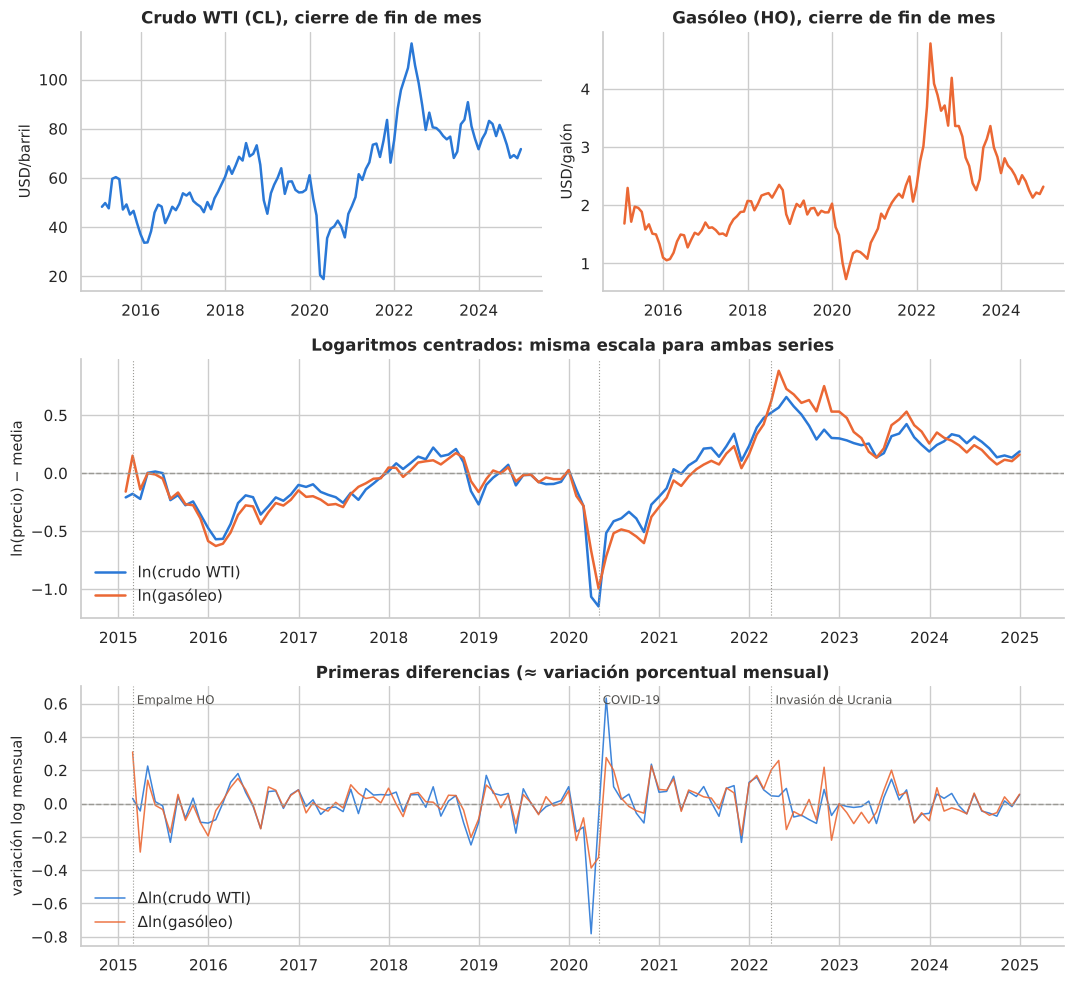

Mayores variaciones absolutas mensuales:


,,|Δln|
fecha,,
2020-03-31,ln_CL,0.782
2020-05-31,ln_CL,0.633
2020-03-31,ln_HO,0.387
2020-04-30,ln_HO,0.324
2015-02-28,ln_HO,0.310


Media de las diferencias y prueba t de media cero (¿hay deriva en los niveles?):


,media mensual,t,p-valor
ln_CL,0.0033,0.2796,0.7803
ln_HO,0.0027,0.2528,0.8009


In [8]:
fig = plt.figure(figsize=(11, 10))
gs = fig.add_gridspec(3, 2)
ax_cl, ax_ho = fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[0, 1])
ax_log = fig.add_subplot(gs[1, :])
ax_dif = fig.add_subplot(gs[2, :], sharex=ax_log)
ax_cl.plot(mensual.index, mensual.iloc[:, 0], color=COL["CL"]); ax_cl.set_ylabel("USD/barril")
ax_cl.set_title("Crudo WTI (CL), cierre de fin de mes")
ax_ho.plot(mensual.index, mensual.iloc[:, 1], color=COL["HO"]); ax_ho.set_ylabel("USD/galón")
ax_ho.set_title("Gasóleo (HO), cierre de fin de mes")
for ax in (ax_cl, ax_ho):
    eje_fechas(ax, 2)

for c in datos:
    ax_log.plot(datos.index, datos[c] - datos[c].mean(), color=COL[c[-2:]], label=ETIQ[c])
    ax_dif.plot(dif.index, dif[c], color=COL[c[-2:]], lw=1.1, alpha=0.9, label=r"$\Delta$" + ETIQ[c])
for ax in (ax_log, ax_dif):
    ax.axhline(0, color=COL["ref"], ls="--", lw=1); ax.legend(loc="lower left")
ax_log.set_ylabel("ln(precio) − media"); ax_log.set_title("Logaritmos centrados: misma escala para ambas series")
ax_dif.set_ylabel("variación log mensual"); ax_dif.set_title("Primeras diferencias (≈ variación porcentual mensual)")
for fecha, txt in [("2020-04-30", "COVID-19"), ("2022-03-31", "Invasión de Ucrania"), ("2015-02-28", "Empalme HO")]:
    for ax in (ax_log, ax_dif):
        ax.axvline(pd.Timestamp(fecha), color=COL["ref"], lw=0.8, ls=":")
    ax_dif.annotate(txt, (pd.Timestamp(fecha), ax_dif.get_ylim()[1] * 0.85), fontsize=8.5, color="#52514e",
                    ha="left", xytext=(3, 0), textcoords="offset points")
eje_fechas(ax_dif)
plt.tight_layout(); plt.show()

print("Mayores variaciones absolutas mensuales:")
display(dif.abs().stack().nlargest(5).rename("|Δln|").round(3).to_frame())
print("Media de las diferencias y prueba t de media cero (¿hay deriva en los niveles?):")
display(pd.DataFrame({"media mensual": dif.mean(), "t": dif.mean() / (dif.std() / np.sqrt(len(dif))),
                      "p-valor": 2 * stats.t.sf(np.abs(dif.mean() / (dif.std() / np.sqrt(len(dif)))), len(dif) - 1)}).round(4))

**Interpretación de los gráficos.**

- **Niveles y logaritmos:** ninguna serie gira alrededor de una media fija; los logaritmos centrados se superponen durante
  casi toda la muestra, lo que sugiere —sin probarlo— una tendencia estocástica común.
- **Diferencias:** oscilan alrededor de cero, con episodios de alta volatilidad. El mayor movimiento mensual del crudo
  ocurre en marzo de 2020 (≈ −0.78 en logaritmos, una caída cercana al 54 %), seguido del rebote de mayo de 2020.
- **Sin deriva:** la variación media mensual es prácticamente nula y no significativa en ambas series. Es una primera
  pista, exploratoria, de que los niveles no tienen tendencia lineal; será relevante para elegir los términos deterministas
  (Módulo 6).
- **Febrero-marzo de 2015 en el gasóleo:** una subida de ≈ 31 % seguida de una caída equivalente. Coincide con el
  vencimiento del contrato de marzo de 2015 en un invierno muy frío; parte del salto puede ser efecto de empalme. No lo
  eliminamos (no hay un dato alternativo verificable), pero lo señalamos como observación influyente.
- **Posibles quiebres:** 2020 (pandemia) y 2022 (choque de oferta tras la invasión de Ucrania). El Módulo 8 los evalúa.

> **Actividad 4.1.** ¿Qué cambiaría si en vez del último cierre usara el promedio mensual? Piense en el efecto sobre la
> autocorrelación de las diferencias.

---
## Módulo 5. Orden de integración

**¿Qué problema resolvemos?** Saber si las series son $I(1)$. **¿Por qué?** La cointegración solo tiene sentido entre
series integradas del mismo orden: si fueran estacionarias bastaría un VAR en niveles; si alguna fuera $I(2)$, el VECM
estándar no sería adecuado. **¿Qué calculamos?** Las pruebas ADF y KPSS en niveles y en diferencias. **¿Cómo lo
interpretaremos?** Leyendo las dos pruebas juntas, porque tienen hipótesis nulas opuestas.

| Prueba | $H_0$ | $H_1$ | Rechazar $H_0$ sugiere |
|---|---|---|---|
| **ADF** | Raíz unitaria | Estacionaria (alrededor de la parte determinista) | Estacionariedad |
| **KPSS** | Estacionaria (alrededor de la parte determinista) | Raíz unitaria | No estacionariedad |

La regresión ADF es $\Delta y_t = a + \delta t + \rho\,y_{t-1} + \sum_{j=1}^{m}\phi_j\Delta y_{t-j} + e_t$, con $H_0:\rho = 0$.
La parte determinista (constante `'c'`, o constante y tendencia `'ct'`) **cambia la pregunta**: con `'ct'` la alternativa es
"estacionaria alrededor de una tendencia lineal".

| ADF | KPSS | Lectura |
|---|---|---|
| No rechaza | Rechaza | Evidencia coherente de raíz unitaria |
| Rechaza | No rechaza | Evidencia coherente de estacionariedad |
| No rechaza | No rechaza | Datos poco informativos (baja potencia): decidir con gráficos y teoría |
| Rechaza | Rechaza | Señales contradictorias: posible quiebre o mala especificación determinista |

**No rechazar una nula no la demuestra.** Con 120 observaciones ambas pruebas tienen potencia limitada. Como no hay un
argumento económico para una tendencia determinista en los logaritmos de precios del petróleo en 2015-2024 (y la variación
media es nula, Módulo 4), la especificación principal es **solo constante**; la de tendencia se reporta como sensibilidad.

In [9]:
def prueba_adf(serie, regresion):
    est, p, rez, _, vc, _ = adfuller(serie.dropna(), regression=regresion, autolag="AIC")
    return est, p, rez, vc["5%"]

def prueba_kpss(serie, regresion):
    est, p, rez, vc = kpss(serie.dropna(), regression=regresion, nlags="auto")
    p_txt = "< 0.01" if p <= 0.01 else ("> 0.10" if p >= 0.10 else f"{p:.3f}")   # statsmodels acota el p-valor
    return est, p, p_txt, vc["5%"]

def tabla_raiz_unitaria(df, sufijo="", regresiones=("c", "ct"), alfa=0.05):
    filas = []
    for col in df.columns:
        for reg in regresiones:
            a_est, a_p, a_rez, a_vc = prueba_adf(df[col], reg)
            k_est, k_p, k_txt, k_vc = prueba_kpss(df[col], reg)
            adf_rech, kpss_rech = a_p < alfa, k_p < alfa
            lectura = {(False, True): "Raíz unitaria (coherente)", (True, False): "Estacionaria (coherente)",
                       (False, False): "No concluyente", (True, True): "Contradictorio"}[(adf_rech, kpss_rech)]
            filas.append({"Serie": sufijo + ETIQ.get(col, col),
                          "Determinista": {"c": "constante", "ct": "const. + tendencia"}[reg],
                          "ADF estad.": a_est, "ADF VC 5%": a_vc, "ADF p": a_p, "ADF rezagos": a_rez,
                          "KPSS estad.": k_est, "KPSS VC 5%": k_vc, "KPSS p": k_txt, "Lectura conjunta": lectura})
    return pd.DataFrame(filas)

tabla_ur = pd.concat([tabla_raiz_unitaria(datos), tabla_raiz_unitaria(dif, sufijo="Δ", regresiones=("c",))],
                     ignore_index=True)
display(tabla_ur.round({"ADF estad.": 3, "ADF VC 5%": 3, "ADF p": 4, "KPSS estad.": 3, "KPSS VC 5%": 3}))

,Serie,Determinista,ADF estad.,ADF VC 5%,ADF p,ADF rezagos,KPSS estad.,KPSS VC 5%,KPSS p,Lectura conjunta
0,ln(crudo WTI),constante,-1.675,-2.887,0.4440,4,0.864,0.463,< 0.01,Raíz unitaria (coherente)
1,ln(crudo WTI),const. + tendencia,-2.895,-3.449,0.1637,2,0.110,0.146,> 0.10,No concluyente
2,ln(gasóleo),constante,-1.922,-2.886,0.3219,1,0.807,0.463,< 0.01,Raíz unitaria (coherente)
3,ln(gasóleo),const. + tendencia,-2.796,-3.448,0.1983,1,0.104,0.146,> 0.10,No concluyente
4,Δln(crudo WTI),constante,-7.133,-2.887,0.0000,3,0.040,0.463,> 0.10,Estacionaria (coherente)
5,Δln(gasóleo),constante,-10.473,-2.886,0.0000,0,0.052,0.463,> 0.10,Estacionaria (coherente)


**Interpretación (valores de la tabla anterior).**

1. **Niveles con constante (especificación principal):** ADF no rechaza la raíz unitaria (p ≈ 0.44 para el crudo y
   ≈ 0.32 para el gasóleo) y KPSS rechaza la estacionariedad al 1 %: **evidencia coherente de no estacionariedad**.
2. **Niveles con constante y tendencia:** ADF sigue sin rechazar (p ≈ 0.16 y ≈ 0.20), pero KPSS ya no rechaza la
   estacionariedad alrededor de una tendencia. Es el caso "no concluyente": con 120 datos no se distingue con claridad
   entre una raíz unitaria y un proceso persistente alrededor de una tendencia. Como no hay razón económica para esa
   tendencia, no le damos más peso, pero dejamos constancia de la ambigüedad.
3. **Primeras diferencias:** ADF rechaza con fuerza la raíz unitaria (p < 0.001) y KPSS no rechaza la estacionariedad:
   las diferencias son $I(0)$, lo que descarta un orden $I(2)$.

**Decisión.** Tratamos ambas series como $I(1)$. Es una conclusión **razonable, no demostrada**.

> **Error frecuente.** Leer "KPSS p-valor = 0.10" como un p-valor exacto. `statsmodels` interpola en una tabla corta y lo
> trunca: significa "0.10 o más".

---
## Módulo 6. Selección de rezagos y prueba de cointegración de Johansen

### 6.1 Rezagos

**¿Qué problema resolvemos?** Elegir cuántos rezagos en diferencias ($\Gamma_1,\dots,\Gamma_{p-1}$) incluir. **¿Por qué?**
Pocos rezagos dejan autocorrelación en los residuos, y entonces ni la prueba de Johansen ni los errores estándar son
válidos; demasiados consumen grados de libertad (con $T=120$, cada rezago agrega $k^2=4$ parámetros) y reducen la potencia.
**¿Qué calculamos?** Criterios de información y, para cada candidato, una prueba de autocorrelación residual.
**¿Cómo lo interpretaremos?** Elegiremos el modelo más pequeño que deje residuos sin autocorrelación.

$\text{IC}(m) = \ln|\hat{\boldsymbol\Sigma}_m| + \frac{c_T}{T}\,N_m$, con $N_m$ parámetros:

| Criterio | Penalización $c_T$ | Tendencia |
|---|---|---|
| AIC | $2$ | Modelos más grandes; orientado a pronóstico |
| BIC | $\ln T$ | El más parsimonioso; consistente si el modelo verdadero está entre los candidatos |
| HQIC | $2\ln\ln T$ | Intermedio |

**Cómo se relacionan los rezagos.** `select_order` de `statsmodels.tsa.vector_ar.vecm` devuelve directamente
`k_ar_diff`, el número de rezagos **en diferencias** del VECM. Si devuelve 0, el VECM no tiene $\Gamma$ y equivale a un
VAR(1) en niveles; si devuelve 2, equivale a un VAR(3). No hay que restarle ni sumarle nada.

Usamos `deterministic="ci"` también aquí, para que la selección de rezagos se haga con la misma especificación
determinista que usaremos en todo el análisis (la justificamos en 6.3).

In [10]:
DETERMINISTICO = "ci"     # constante restringida a la relación de cointegración (justificación en 6.3 y 7.2)
MAX_REZAGOS = 12
sel = select_order(datos, maxlags=MAX_REZAGOS, deterministic=DETERMINISTICO)
print(sel.summary())
rez_sugeridos = {"AIC": int(sel.aic), "BIC": int(sel.bic), "HQIC": int(sel.hqic), "FPE": int(sel.fpe)}
print("k_ar_diff sugerido:", rez_sugeridos, "→ VAR en niveles de orden p =", {k: v + 1 for k, v in rez_sugeridos.items()})

filas = []
for kd in range(0, 4):
    r_ = VECM(datos, k_ar_diff=kd, coint_rank=1, deterministic=DETERMINISTICO).fit()
    w = r_.test_whiteness(nlags=12, adjusted=True)
    filas.append({"k_ar_diff": kd, "VAR equivalente": f"VAR({kd + 1})",
                  "lo elige": ", ".join(n for n, v in rez_sugeridos.items() if v == kd) or "—",
                  "Portmanteau (12) estad.": w.test_statistic, "p-valor": w.pvalue})
display(pd.DataFrame(filas).set_index("k_ar_diff").round(4))

 VECM Order Selection (* highlights the minimums) 
       AIC         BIC         FPE         HQIC   
--------------------------------------------------
0       -9.648     -9.448*   6.456e-05     -9.567*
1       -9.646      -9.346   6.470e-05      -9.524
2      -9.664*      -9.264  6.358e-05*      -9.502
3       -9.600      -9.101   6.779e-05      -9.398
4       -9.620      -9.021   6.650e-05      -9.377
5       -9.555      -8.856   7.104e-05      -9.272
6       -9.514      -8.715   7.415e-05      -9.190
7       -9.456      -8.557   7.872e-05      -9.092
8       -9.396      -8.397   8.382e-05      -8.991
9       -9.331      -8.232   8.972e-05      -8.885
10      -9.284      -8.085   9.433e-05      -8.798
11      -9.232      -7.933   9.985e-05      -8.705
12      -9.199      -7.800   0.0001037      -8.632
--------------------------------------------------
k_ar_diff sugerido: {'AIC': 2, 'BIC': 0, 'HQIC': 0, 'FPE': 2} → VAR en niveles de orden p = {'AIC': 3, 'BIC': 1, 'HQIC': 1, 'FPE': 3}

,VAR equivalente,lo elige,Portmanteau (12) estad.,p-valor
k_ar_diff,,,,
0,VAR(1),"BIC, HQIC",45.2164,0.5050
1,VAR(2),—,39.1320,0.5976
2,VAR(3),"AIC, FPE",28.7238,0.8615
3,VAR(4),—,28.9912,0.7116


**Interpretación y decisión.** BIC y HQIC eligen `k_ar_diff = 0`; AIC y FPE eligen 2. La superficie de AIC es muy plana,
así que las diferencias entre criterios son pequeñas. La prueba Portmanteau multivariada no detecta autocorrelación
residual en ningún candidato, incluido el de 0 rezagos. Adoptamos **`k_ar_diff = 0`** (BIC): es el modelo más pequeño
que deja residuos sin autocorrelación, y con $T=120$ la parsimonia ayuda a estimar mejor la relación de largo plazo. La
alternativa de AIC (`k_ar_diff = 2`) se mantiene en los análisis de sensibilidad y compite en la validación de pronósticos.

> **Actividad 6.1 (antes de ejecutar Johansen).** Con lo visto hasta ahora —series $I(1)$, gráficos que se mueven juntos,
> un argumento económico de margen de refinación—, ¿cuántas relaciones de cointegración esperaría encontrar entre dos
> precios? ¿Qué resultado le haría dudar del argumento económico? ¿Y uno que le haría dudar de las pruebas de raíz unitaria?

### 6.2 La prueba de Johansen: idea e hipótesis

**¿Qué problema resolvemos?** Determinar el rango $r$ de $\boldsymbol\Pi$, es decir, cuántas combinaciones lineales
estacionarias existen. **¿Por qué?** Porque el rango decide el modelo: VAR en diferencias ($r=0$), VECM ($0<r<k$) o VAR en
niveles ($r=k$). **¿Qué calculamos?** Los autovalores $\hat\lambda_1>\dots>\hat\lambda_k$ de un problema de correlación
canónica entre $\Delta\mathbf y_t$ y $\mathbf y_{t-1}$, una vez filtrada la dinámica de corto plazo (detalles en el
**Apéndice B**). Un autovalor grande indica una combinación de los niveles que ayuda a predecir los cambios: una relación de
cointegración. **¿Cómo lo interpretaremos?** Con dos estadísticos y un procedimiento secuencial:

| Estadístico | Fórmula | $H_0$ | $H_1$ |
|---|---|---|---|
| Traza | $\lambda_{traza}(r_0) = -T\sum_{i=r_0+1}^{k}\ln(1-\hat\lambda_i)$ | $r \le r_0$ | $r > r_0$ |
| Máximo autovalor | $\lambda_{max}(r_0) = -T\ln(1-\hat\lambda_{r_0+1})$ | $r = r_0$ | $r = r_0+1$ |

Se empieza con $r_0=0$; si se rechaza, se pasa a $r_0=1$, y así hasta el primer $r_0$ que no se rechaza. Con $k=2$:
la primera prueba pregunta "¿hay al menos una relación?" y la segunda "¿hay dos, es decir, son ambas series estacionarias?".
Los estadísticos **no** siguen una $\chi^2$: sus valores críticos dependen de $k-r_0$ y de los términos deterministas.

### 6.3 Términos deterministas: cinco casos y por qué usamos la constante restringida

| Caso de Johansen | Qué permite | `VECM(deterministic=)` | `coint_johansen(det_order=)` |
|---|---|---|---|
| 1. Sin términos | Relación por el origen, sin deriva | `"n"` | `-1` |
| 2. **Constante restringida** | Constante en la relación de equilibrio, **sin deriva** en los niveles | **`"ci"`** | **no disponible** |
| 3. Constante sin restringir | Constante en la relación **y deriva** lineal en los niveles | `"co"` | `0` |
| 4. Tendencia restringida | Tendencia en la relación, deriva en los niveles | `"coli"` | no disponible |
| 5. Tendencia sin restringir | Tendencia cuadrática en los niveles | `"colo"` | `1` (aprox.) |

Para los logaritmos del crudo y del gasóleo, el caso económicamente coherente es el **2**: la relación de equilibrio
necesita una constante (los precios están en unidades distintas y hay un margen medio), pero los precios no tienen una
deriva sistemática (variación media nula, Módulo 4). En el Módulo 7 lo contrastamos formalmente.

Esto tiene una consecuencia práctica: `coint_johansen` no ofrece el caso 2. Si probáramos el rango con `det_order=0`
(caso 3) y estimáramos con `"ci"` (caso 2), estaríamos usando especificaciones distintas en la prueba y en el modelo.
Además, los valores críticos del caso 3 se derivan suponiendo que los niveles **sí** tienen deriva; cuando no la tienen,
la distribución de la última prueba cambia y los valores tabulados dejan de ser adecuados (Nielsen y Rahbek, 2000).

Por eso implementamos la prueba directamente. La función `johansen` sigue el procedimiento del Apéndice B y la
validamos de dos formas: en el caso 3 debe reproducir exactamente a `coint_johansen`, y en el caso 2 su vector debe
coincidir con el $\hat\beta$ de `VECM(..., deterministic="ci")`.

In [11]:
def johansen(Y, k_ar_diff, caso="ci"):
    # Prueba de Johansen. caso="co": constante sin restringir (caso 3); caso="ci": constante restringida (caso 2).
    Y = np.asarray(Y, float)
    k, p = Y.shape[1], k_ar_diff
    if Y.shape[0] <= k * (p + 2):
        raise ValueError("Muy pocas observaciones para el número de rezagos")
    dY = np.diff(Y, axis=0)
    Z0, Z1 = dY[p:], Y[p:-1]                       # Δy_t y y_{t-1}
    n = Z0.shape[0]
    Z2 = np.column_stack([dY[p - j:-j] for j in range(1, p + 1)]) if p > 0 else np.empty((n, 0))
    if caso == "co":
        Z2 = np.column_stack([np.ones(n), Z2])     # la constante filtra ambos lados
    elif caso == "ci":
        Z1 = np.column_stack([Z1, np.ones(n)])     # la constante entra junto a los niveles
    else:
        raise ValueError("caso debe ser 'co' o 'ci'")
    resid = lambda A, B: A if B.shape[1] == 0 else A - B @ np.linalg.lstsq(B, A, rcond=None)[0]
    R0, R1 = resid(Z0, Z2), resid(Z1, Z2)
    S00, S11, S01 = R0.T @ R0 / n, R1.T @ R1 / n, R0.T @ R1 / n
    lam, vec = np.linalg.eig(np.linalg.solve(S11, S01.T @ np.linalg.solve(S00, S01)))
    orden = np.argsort(np.real(lam))[::-1][:k]
    lam, vec = np.real(lam[orden]), np.real(vec[:, orden])
    return {"autovalores": lam, "traza": np.array([-n * np.log(1 - lam[r:]).sum() for r in range(k)]),
            "maxeig": -n * np.log(1 - lam), "vectores": vec, "n": n}

K_AR_DIFF = int(sel.bic)
print("Validación 1 — caso 3 ('co') frente a statsmodels (estadísticos de traza):")
for kd in range(0, 4):
    print(f"   k_ar_diff = {kd}: propia {np.round(johansen(datos, kd, 'co')['traza'], 4)} | "
          f"statsmodels {np.round(coint_johansen(datos, 0, kd).lr1, 4)}")
j_ci = johansen(datos, K_AR_DIFF, "ci")
v = j_ci["vectores"][:, 0] / j_ci["vectores"][0, 0]
r_chk = VECM(datos, k_ar_diff=K_AR_DIFF, coint_rank=1, deterministic="ci").fit()
print("Validación 2 — caso 2 ('ci') frente a VECM('ci'):")
print("   vector propio [ln_CL, ln_HO, constante]:", np.round(v, 4))
print("   VECM('ci')    [ln_CL, ln_HO] + μ₀      :", np.round(r_chk.beta[:, 0], 4), np.round(r_chk.det_coef_coint[0, 0], 4))

Validación 1 — caso 3 ('co') frente a statsmodels (estadísticos de traza):
   k_ar_diff = 0: propia [36.7149  4.2934] | statsmodels [36.4043  4.2971]
   k_ar_diff = 1: propia [40.0157  3.4831] | statsmodels [40.0157  3.4831]
   k_ar_diff = 2: propia [28.9292  5.0855] | statsmodels [28.9292  5.0855]
   k_ar_diff = 3: propia [25.51    4.3111] | statsmodels [25.51    4.3111]
Validación 2 — caso 2 ('ci') frente a VECM('ci'):
   vector propio [ln_CL, ln_HO, constante]: [ 1.     -0.8447 -3.5093]
   VECM('ci')    [ln_CL, ln_HO] + μ₀      : [ 1.     -0.8447] -3.5093


**Lectura de las validaciones.** Con 1, 2 y 3 rezagos la función reproduce exactamente a `coint_johansen`, y en el caso 2
genera el mismo vector que el estimador VECM. Con `k_ar_diff = 0` aparece una pequeña diferencia: revisando el código fuente
de `coint_johansen` (serie 0.14), con cero rezagos la función empareja $\Delta\mathbf y_t$ con $\mathbf y_t$ en lugar de con
$\mathbf y_{t-1}$; con uno o más rezagos usa $\mathbf y_{t-k}$, una reparametrización equivalente. Nuestra función usa
$\mathbf y_{t-1}$, como indica la definición. Aquí la diferencia (36.71 frente a 36.40) no cambia ninguna decisión, pero
es otra razón para no depender de `coint_johansen` cuando `k_ar_diff = 0`. Conviene revisarlo en versiones futuras de la
biblioteca.

Falta el último ingrediente: los **valores críticos** del caso 2. Osterwald-Lenum (1992)
los tabula; para la traza con $m = k-r_0$ tendencias estocásticas bajo $H_0$: $m=2$: 17.85 / 19.96 / 24.60 y $m=1$:
7.52 / 9.24 / 12.97 (90 / 95 / 99 %). En lugar de copiarlos sin más, **los reproducimos por simulación**: generamos paseos
aleatorios independientes (la situación bajo $H_0$) y calculamos la distribución de los estadísticos. La misma simulación
da los p-valores. Como ilustración, simulamos también el caso 3 sin deriva para ver por qué su valor crítico tabulado (3.84)
no sirve cuando los niveles no tienen tendencia.

In [12]:
def distribucion_nula(m, caso="ci", T=500, reps=5000, semilla=SEMILLA):
    rng_j = np.random.default_rng(semilla)
    tr, mx = np.empty(reps), np.empty(reps)
    for i in range(reps):
        res_j = johansen(np.cumsum(rng_j.standard_normal((T, m)), axis=0), 0, caso)
        tr[i], mx[i] = res_j["traza"][0], res_j["maxeig"][0]
    return tr, mx

DIST = {m: distribucion_nula(m) for m in (2, 1)}
VC_TABLA_TRAZA = {2: (17.85, 19.96, 24.60), 1: (7.52, 9.24, 12.97)}     # Osterwald-Lenum (1992), caso 2
cuantiles = lambda x: np.quantile(x, [0.90, 0.95, 0.99])
display(pd.DataFrame({"traza m=2 (tabla)": VC_TABLA_TRAZA[2], "traza m=2 (sim.)": cuantiles(DIST[2][0]),
                      "máx. autov. m=2 (sim.)": cuantiles(DIST[2][1]),
                      "traza m=1 (tabla)": VC_TABLA_TRAZA[1], "traza m=1 (sim.)": cuantiles(DIST[1][0])},
                     index=["90%", "95%", "99%"]).round(2))

tr_co_sin_deriva, _ = distribucion_nula(1, caso="co", reps=3000)
print(f"Caso 3 con niveles SIN deriva, m=1: percentil 95% simulado = {np.quantile(tr_co_sin_deriva, 0.95):.2f} "
      f"(valor tabulado del caso 3, que supone deriva: 3.84)")

,traza m=2 (tabla),traza m=2 (sim.),máx. autov. m=2 (sim.),traza m=1 (tabla),traza m=1 (sim.)
90%,17.85,17.91,13.81,7.52,7.36
95%,19.96,20.11,15.79,9.24,8.93
99%,24.60,24.62,19.84,12.97,12.24


Caso 3 con niveles SIN deriva, m=1: percentil 95% simulado = 8.04 (valor tabulado del caso 3, que supone deriva: 3.84)


,autovalor,traza,VC 95% traza,p traza,máx. autov.,VC 95% máx.,p máx.,decisión 5%
H0 (traza),,,,,,,,
r ≤ 0,0.2385,36.7975,20.1087,0.0004,32.4218,15.7866,0.0002,rechaza
r ≤ 1,0.0361,4.3757,8.9312,0.3442,4.3757,8.9312,0.3442,no rechaza


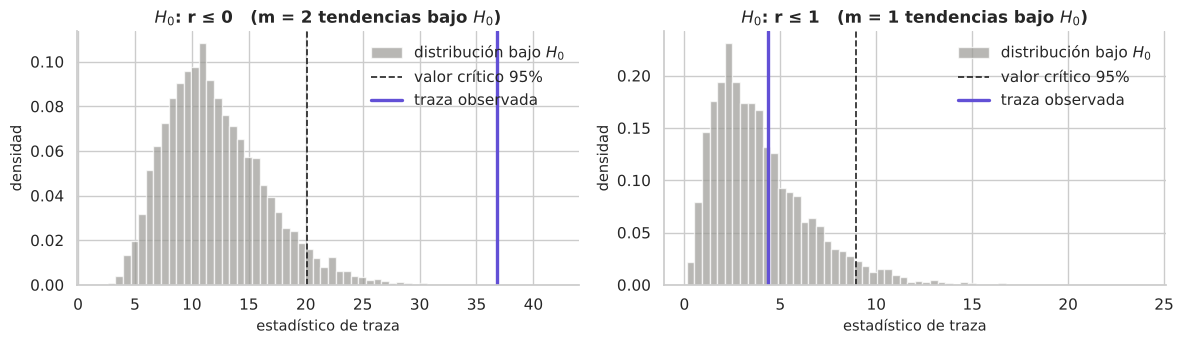

In [13]:
k = datos.shape[1]
filas = []
for r0 in range(k):
    m = k - r0
    tr_obs, mx_obs = j_ci["traza"][r0], j_ci["maxeig"][r0]
    filas.append({"H0 (traza)": f"r ≤ {r0}", "autovalor": j_ci["autovalores"][r0],
                  "traza": tr_obs, "VC 95% traza": np.quantile(DIST[m][0], 0.95), "p traza": np.mean(DIST[m][0] >= tr_obs),
                  "máx. autov.": mx_obs, "VC 95% máx.": np.quantile(DIST[m][1], 0.95), "p máx.": np.mean(DIST[m][1] >= mx_obs)})
tabla_joh = pd.DataFrame(filas).set_index("H0 (traza)")
tabla_joh["decisión 5%"] = np.where(tabla_joh["p traza"] < 0.05, "rechaza", "no rechaza")
display(tabla_joh.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
for ax, r0 in zip(axes, (0, 1)):
    m = k - r0
    ax.hist(DIST[m][0], bins=60, color=COL["ref"], alpha=0.7, density=True, label="distribución bajo $H_0$")
    ax.axvline(np.quantile(DIST[m][0], 0.95), color=COL["obs"], ls="--", lw=1.2, label="valor crítico 95%")
    ax.axvline(j_ci["traza"][r0], color=COL["ECT"], lw=2.4, label="traza observada")
    ax.set_title(f"$H_0$: r ≤ {r0}   (m = {m} tendencias bajo $H_0$)")
    ax.set_xlabel("estadístico de traza"); ax.set_ylabel("densidad"); ax.legend()
plt.tight_layout(); plt.show()

**Interpretación.**

- Los valores críticos simulados reproducen los tabulados por Osterwald-Lenum con diferencias pequeñas, propias del error
  de simulación y de usar $T$ finito.
- **$H_0: r = 0$** se rechaza con holgura con ambos estadísticos: la traza observada queda muy a la derecha de toda la
  distribución simulada.
- **$H_0: r \le 1$** no se rechaza: el estadístico (≈ 4.4) cae en el centro de su distribución bajo la nula.
- **Conclusión estadística: $r=1$**. Hay una combinación estacionaria de los dos precios y una tendencia estocástica común.

La simulación del caso 3 sin deriva muestra el problema: su percentil 95 % es mucho mayor que 3.84. Si hubiéramos usado
`coint_johansen(det_order=0)` con su valor tabulado, el mismo estadístico (≈ 4.3) habría llevado a rechazar $r\le1$ y a
concluir que ambas series son estacionarias, en contradicción con el Módulo 5. El error no estaría en los datos, sino en
usar valores críticos que suponen una deriva que los precios no tienen.

### 6.4 ¿Depende de los rezagos y de la especificación determinista?

In [14]:
filas = []
for kd in range(0, 4):
    jj_ci, jj_co = johansen(datos, kd, "ci"), johansen(datos, kd, "co")
    vc_co = coint_johansen(datos, 0, kd).cvt          # valores críticos tabulados del caso 3 (90/95/99 %)
    r_ci = 0 if jj_ci["traza"][0] <= np.quantile(DIST[2][0], 0.95) else (1 if jj_ci["traza"][1] <= np.quantile(DIST[1][0], 0.95) else 2)
    r_co = 0 if jj_co["traza"][0] <= vc_co[0, 1] else (1 if jj_co["traza"][1] <= vc_co[1, 1] else 2)
    filas.append({"k_ar_diff": kd, "VAR equiv.": f"VAR({kd + 1})",
                  "caso 2 traza r≤0": jj_ci["traza"][0], "caso 2 traza r≤1": jj_ci["traza"][1], "caso 2: r (5%)": r_ci,
                  "caso 3 traza r≤0": jj_co["traza"][0], "caso 3 traza r≤1": jj_co["traza"][1],
                  "caso 3: r con VC tabulados (5%)": r_co})
display(pd.DataFrame(filas).set_index("k_ar_diff").round(2))

,VAR equiv.,caso 2 traza r≤0,caso 2 traza r≤1,caso 2: r (5%),caso 3 traza r≤0,caso 3 traza r≤1,caso 3: r con VC tabulados (5%)
k_ar_diff,,,,,,,
0,VAR(1),36.80,4.38,1,36.71,4.29,2
1,VAR(2),40.21,3.48,1,40.02,3.48,1
2,VAR(3),29.03,5.15,1,28.93,5.09,2
3,VAR(4),25.60,4.37,1,25.51,4.31,2


**Lectura.** Con la especificación coherente (caso 2) la prueba elige $r=1$ con 0, 1, 2 o 3 rezagos: la conclusión
**no depende** del número de rezagos. Con el caso 3 y sus valores tabulados el resultado oscila entre $r=1$ y $r=2$ según
los rezagos: esa inestabilidad es un síntoma de usar una especificación determinista inadecuada, no una propiedad de los datos.

### 6.5 Rango estadístico frente a interpretación económica

Que $r=1$ significa, estadísticamente, que existe **una** combinación lineal estacionaria y **una** tendencia estocástica
común. No dice, por sí solo, que esa combinación sea "el margen de refinación", ni qué precio impulsa la tendencia común.
Esa lectura económica es una hipótesis que debe ser coherente con los signos y magnitudes de $\hat\beta$ y $\hat\alpha$
(Módulo 7). Tampoco basta que las gráficas se muevan juntas: la evidencia de cointegración procede de la prueba, no de la
inspección visual.

> **Actividad 6.2.** Explique con sus palabras por qué, con $k=2$, la prueba de $H_0: r\le 1$ es en esencia una prueba de
> raíz unitaria sobre la tendencia común. ¿Qué implicaría rechazarla para los resultados del Módulo 5?

---
## Módulo 7. Estimación e interpretación del VECM

**¿Qué problema resolvemos?** Estimar la relación de equilibrio y las velocidades de ajuste. **¿Por qué?** Porque son las
respuestas a las preguntas económicas 1 y 2. **¿Qué calculamos?** El VECM con $r=1$, `k_ar_diff = 0` y constante
restringida:

$$\Delta\mathbf y_t = \boldsymbol\alpha\,\big(\boldsymbol\beta'\mathbf y_{t-1} + \mu_0\big) + \boldsymbol\varepsilon_t,
\qquad \mathbf y_t = (\ln CL_t,\ \ln HO_t)',\qquad \boldsymbol\beta = (1,\ \beta_2)' .$$

**¿Cómo lo interpretaremos?** $\boldsymbol\beta$ y $\mu_0$ definen el equilibrio; $ECT_t = \ln CL_t + \beta_2\ln HO_t + \mu_0$
mide la distancia a él; $\boldsymbol\alpha$ dice cómo reacciona cada precio a esa distancia.

In [15]:
COINT_RANK = 1
vecm_res = VECM(datos, k_ar_diff=K_AR_DIFF, coint_rank=COINT_RANK, deterministic=DETERMINISTICO).fit()
b2, mu0 = vecm_res.beta[1, 0], vecm_res.det_coef_coint[0, 0]
print(f"Especificación: r = {COINT_RANK}, k_ar_diff = {K_AR_DIFF}, deterministic = '{DETERMINISTICO}'")
print(f"Observaciones efectivas: {vecm_res.nobs}  (T = {len(datos)} menos {K_AR_DIFF + 1})")

ic_beta = vecm_res.conf_int_beta(alpha=0.05)
ic_mu = vecm_res.conf_int_det_coef_coint(alpha=0.05)
tabla_beta = pd.DataFrame({
    "estimación": [1.0, b2, mu0],
    "error est.": [np.nan, vecm_res.stderr_beta[1, 0], vecm_res.stderr_det_coef_coint[0, 0]],
    "IC 95% inf": [np.nan, ic_beta[1, 0][0], ic_mu[0, 0][0]],
    "IC 95% sup": [np.nan, ic_beta[1, 0][1], ic_mu[0, 0][1]],
}, index=["β ln_CL (normalizado)", "β ln_HO", "μ₀ (constante de la relación)"])
print("\nRelación de cointegración: ECT = ln_CL + β₂·ln_HO + μ₀")
display(tabla_beta.round(4))
print(f"Equilibrio:  ln CL = {-mu0:.3f} + {-b2:.3f} · ln HO")

tabla_alpha = pd.DataFrame({"α": vecm_res.alpha[:, 0], "error est.": vecm_res.stderr_alpha[:, 0],
                            "z": vecm_res.tvalues_alpha[:, 0], "p-valor": vecm_res.pvalues_alpha[:, 0]},
                           index=["ecuación Δln_CL", "ecuación Δln_HO"])
print("Coeficientes de ajuste:")
display(tabla_alpha.round(4))
beta_alpha = (vecm_res.beta.T @ vecm_res.alpha).item()
print(f"β'α = {beta_alpha:.4f}")

Especificación: r = 1, k_ar_diff = 0, deterministic = 'ci'
Observaciones efectivas: 119  (T = 120 menos 1)

Relación de cointegración: ECT = ln_CL + β₂·ln_HO + μ₀


,estimación,error est.,IC 95% inf,IC 95% sup
β ln_CL (normalizado),1.0000,NaN,NaN,NaN
β ln_HO,-0.8447,0.0458,-0.9345,-0.7549
μ₀ (constante de la relación),-3.5093,0.0349,-3.5776,-3.4409


Equilibrio:  ln CL = 3.509 + 0.845 · ln HO
Coeficientes de ajuste:


,α,error est.,z,p-valor
ecuación Δln_CL,-0.1754,0.1233,-1.4218,0.1551
ecuación Δln_HO,0.2479,0.1084,2.2866,0.0222


β'α = -0.3848


### 7.1 ¿Constante dentro o fuera? Comparación sin mezclar parámetros

Estimamos también el modelo con constante sin restringir (`"co"`) y comparamos. Cada especificación se lee con **sus
propios** parámetros. El contraste formal de "sin deriva" es una razón de verosimilitudes: bajo $H_0$ la constante vive
solo dentro de la relación ($\mathbf c = \boldsymbol\alpha\mu_0$), lo que impone $k-r = 1$ restricción, y
$LR = 2(\ell_{co} - \ell_{ci}) \sim \chi^2_1$ asintóticamente (Johansen, 1995).

In [16]:
res_co = VECM(datos, k_ar_diff=K_AR_DIFF, coint_rank=COINT_RANK, deterministic="co").fit()
c_co = res_co.det_coef[:, 0]
comp_det = pd.DataFrame({
    "'ci' (principal)": [vecm_res.beta[1, 0], mu0, vecm_res.alpha[0, 0], vecm_res.alpha[1, 0], np.nan, np.nan, vecm_res.alpha[0, 0] * mu0, vecm_res.alpha[1, 0] * mu0],
    "'co' (sensibilidad)": [res_co.beta[1, 0], np.nan, res_co.alpha[0, 0], res_co.alpha[1, 0], c_co[0], c_co[1], np.nan, np.nan],
}, index=["β₂", "μ₀ (dentro de la relación)", "α ln_CL", "α ln_HO", "c ln_CL (fuera)", "c ln_HO (fuera)",
          "α·μ₀ ln_CL", "α·μ₀ ln_HO"])
display(comp_det.round(4))

lr_det = 2 * (np.real(res_co.llf) - np.real(vecm_res.llf))
print(f"LR ('ci' frente a 'co') = {lr_det:.3f}, p-valor χ²(1) = {stats.chi2.sf(lr_det, 1):.3f}")
a_perp = np.array([-res_co.alpha[1, 0], res_co.alpha[0, 0]])
print(f"Deriva implícita en el modelo 'co' (α⊥'c): {a_perp @ c_co:.5f}")
print(f"Media de β'y SIN la constante: {np.mean(datos.values @ vecm_res.beta[:, 0]):.3f}   "
      f"| media del ECT con μ₀: {np.mean(datos.values @ vecm_res.beta[:, 0] + mu0):.4f}")

,'ci' (principal),'co' (sensibilidad)
β₂,-0.8447,-0.8447
μ₀ (dentro de la relación),-3.5093,NaN
α ln_CL,-0.1754,-0.1753
α ln_HO,0.2479,0.2480
c ln_CL (fuera),NaN,0.6184
c ln_HO (fuera),NaN,-0.8675
α·μ₀ ln_CL,0.6155,NaN
α·μ₀ ln_HO,-0.8700,NaN


LR ('ci' frente a 'co') = 0.082, p-valor χ²(1) = 0.774
Deriva implícita en el modelo 'co' (α⊥'c): -0.00130
Media de β'y SIN la constante: 3.509   | media del ECT con μ₀: 0.0002


**Interpretación.**

- $\hat\beta_2$ y $\hat\alpha$ son prácticamente iguales en ambas especificaciones.
- En `"co"`, las constantes de cada ecuación ($c_{CL}\approx 0.62$, $c_{HO}\approx -0.87$) parecen grandes, pero coinciden casi
  exactamente con $\hat\alpha\hat\mu_0$ del modelo `"ci"`: son la constante de la relación de equilibrio "repartida" entre
  las ecuaciones, no una deriva. La deriva implícita es prácticamente cero.
- La prueba LR no rechaza la restricción (p ≈ 0.77): los datos son compatibles con que la constante esté solo dentro de la
  relación. Eso, junto con el argumento económico y la variación media nula, **justifica `"ci"`**.
- Sin $\mu_0$, la combinación $\beta'\mathbf y_t$ tiene media ≈ 3.51; con $\mu_0$ el ECT está centrado en cero. Por eso,
  en `"co"`, graficar $\beta'\mathbf y_t$ como si fuera el desequilibrio lo desplazaría y, sobre todo, **no se debe tomar
  $\mu_0$ de un modelo `"ci"` para completar el equilibrio de un modelo `"co"`**: cada especificación tiene sus parámetros.

### 7.2 La relación de largo plazo y el ECT

Ejemplo 2024-12: CL = 71.72 USD/barril, HO = 2.3206 USD/galón
   ln CL = 4.2728;  ln HO = 0.8418
   ln CL de equilibrio = 3.509 + 0.8447 × 0.8418 = 4.2204
   ECT = 4.2728 − 4.2204 = +0.0524  (crudo ≈ +5.4 % respecto a su valor de equilibrio)


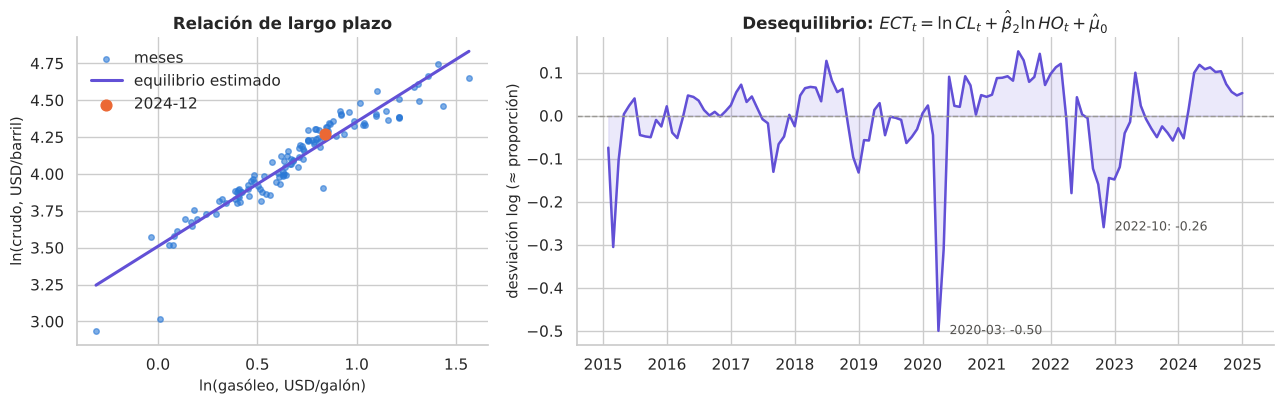

In [17]:
ect = pd.Series(datos.values @ vecm_res.beta[:, 0] + mu0, index=datos.index, name="ECT")

# Ejemplo numérico con un mes concreto
mes = "2024-12-31"
p_cl, p_ho = mensual.loc[mes].values
print(f"Ejemplo {mes[:7]}: CL = {p_cl:.2f} USD/barril, HO = {p_ho:.4f} USD/galón")
print(f"   ln CL = {np.log(p_cl):.4f};  ln HO = {np.log(p_ho):.4f}")
print(f"   ln CL de equilibrio = {-mu0:.3f} + {-b2:.4f} × {np.log(p_ho):.4f} = {-mu0 - b2 * np.log(p_ho):.4f}")
print(f"   ECT = {np.log(p_cl):.4f} − {-mu0 - b2 * np.log(p_ho):.4f} = {ect.loc[mes]:+.4f}  "
      f"(crudo ≈ {100 * (np.exp(ect.loc[mes]) - 1):+.1f} % respecto a su valor de equilibrio)")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1, 1.7]})
xg = np.linspace(datos["ln_HO"].min(), datos["ln_HO"].max(), 50)
axes[0].scatter(datos["ln_HO"], datos["ln_CL"], s=16, color=COL["CL"], alpha=0.6, label="meses")
axes[0].plot(xg, -mu0 - b2 * xg, color=COL["ECT"], lw=2.2, label="equilibrio estimado")
axes[0].scatter([np.log(p_ho)], [np.log(p_cl)], s=60, color=COL["HO"], zorder=3, label=f"{mes[:7]}")
axes[0].set_xlabel("ln(gasóleo, USD/galón)"); axes[0].set_ylabel("ln(crudo, USD/barril)")
axes[0].set_title("Relación de largo plazo"); axes[0].legend(loc="upper left")

axes[1].plot(ect.index, ect, color=COL["ECT"])
axes[1].axhline(0, color=COL["ref"], ls="--", lw=1)
axes[1].fill_between(ect.index, ect, 0, color=COL["ECT"], alpha=0.12)
for f in (ect.idxmin(), ect.loc["2022"].idxmin()):
    axes[1].annotate(f"{f:%Y-%m}: {ect[f]:+.2f}", (f, ect[f]), xytext=(8, 0), textcoords="offset points",
                     fontsize=9, color="#52514e", va="center")
axes[1].set_title(r"Desequilibrio: $ECT_t = \ln CL_t + \hat\beta_2 \ln HO_t + \hat\mu_0$")
axes[1].set_ylabel("desviación log (≈ proporción)"); eje_fechas(axes[1])
plt.tight_layout(); plt.show()

**Cómo leer $\hat\beta$ y $\mu_0$.** La relación estimada es aproximadamente $\ln CL = 3.51 + 0.845\,\ln HO$.

- **Ejemplo numérico (elasticidad).** Si el gasóleo es un 10 % más caro, el precio de equilibrio del crudo es
  $0.845\times 10\%\approx 8.4\%$ más alto. Leído al revés, un crudo 10 % más caro se asocia con un gasóleo de equilibrio
  ≈ 11.8 % más caro ($1/0.845\approx 1.18$).
- **La constante.** $3.51$ refleja sobre todo el cambio de unidades (barril frente a galón) y el margen medio; no tiene una
  lectura económica aislada.
- **Homogeneidad.** Si ambos precios se movieran uno a uno en el largo plazo, sería $\beta_2=-1$. El intervalo al 95 %
  para $\beta_2$, aproximadamente $[-0.93,\,-0.75]$, no contiene a −1: con la muestra completa los datos no respaldan la
  homogeneidad estricta (el Módulo 8 muestra que esto depende del período).
- **Normalización ≠ causalidad.** Escribir la relación "despejando" $\ln CL$ es una convención; no afirma que el gasóleo
  determine al crudo. Identificar una relación estructural (por ejemplo, una ecuación de oferta de refinación) exigiría
  restricciones de la teoría, no una normalización.

**El ECT.** Es la distancia, en logaritmos, entre el crudo observado y el que correspondería al equilibrio dado el gasóleo.
Un $ECT>0$ indica crudo caro **relativo** al gasóleo (margen de refinación bajo); un $ECT<0$, crudo barato relativo al
gasóleo (margen alto). Los episodios más negativos son marzo de 2020 y la segunda mitad de 2022, cuando el margen de los
destilados alcanzó máximos.

> **Actividad 7.1 (después de estimar β).** Escriba la relación de largo plazo en términos de niveles de precio (no de
> logaritmos). Si el gasóleo cuesta 2.50 USD/galón, ¿cuál es el precio de equilibrio del crudo? ¿Por qué esa cifra no es un
> pronóstico del precio del crudo?

### 7.3 Cómo leer $\hat\alpha$: quién corrige y exogeneidad débil

Con $ECT = \ln CL - 0.845\ln HO - 3.51$:

- $\hat\alpha_{CL}\approx -0.175$ (p ≈ 0.16): el crudo tendería a bajar cuando está caro relativo al gasóleo, pero el
  coeficiente no es significativo. No se rechaza la **exogeneidad débil** del crudo ($H_0:\alpha_{CL}=0$, prueba de Wald con
  el estadístico $z$ de la tabla).
- $\hat\alpha_{HO}\approx +0.248$ (p ≈ 0.02): el gasóleo **sube** cuando el crudo está caro relativo a él. Con esta
  normalización, ese signo positivo es exactamente el que corrige el desequilibrio.
- $\hat\beta'\hat\alpha = -0.175 - 0.845\times 0.248 \approx -0.385 < 0$: el sistema en conjunto corrige los desvíos.

**Ejemplo numérico (α negativo y corrección total).** Si este mes el crudo está 10 % por encima de su equilibrio
($ECT = 0.10$), el mes siguiente, en promedio y por este canal: $\Delta\ln CL \approx -0.175\times0.10 = -1.75\%$ y
$\Delta\ln HO\approx 0.248\times 0.10 = +2.48\%$. El nuevo desequilibrio es $0.10 - 0.0175 - 0.845\times0.0248\approx 0.0615$:
se cierra ≈ 38.5 % de la brecha, que es $-\hat\beta'\hat\alpha$. El gasóleo hace la mayor parte del ajuste.

> **Actividad 7.2 (después de estimar α).** ¿Qué variable responde al desequilibrio? ¿Qué significa, en términos de mercado,
> que no se rechace la exogeneidad débil del crudo? ¿Qué pasaría con el signo de $\hat\alpha_{HO}$ si normalizáramos $\beta$
> sobre el gasóleo?

### 7.4 Contribución del ECT frente a la variación total pronosticada

El término $\boldsymbol\alpha\,ECT_{t-1}$ es solo **una parte** de la variación esperada. Con rezagos, la variación
pronosticada es $\widehat{\Delta\mathbf y}_{t+1} = \hat{\boldsymbol\alpha}\,ECT_t + \sum_i\hat{\boldsymbol\Gamma}_i\Delta\mathbf y_{t+1-i}$ (más
constantes no restringidas, si las hubiera). La tabla siguiente descompone el pronóstico de enero de 2025 en el modelo
principal (sin $\Gamma$) y en la alternativa con dos rezagos elegida por AIC.

In [18]:
def descomponer_pronostico(res, datos_m):
    # Descompone el cambio pronosticado para t+1 en el aporte del ECT y el de cada Γ_i
    ect_T = float(datos_m.values[-1] @ res.beta[:, 0] + res.det_coef_coint[0, 0])
    partes = {"α·ECT": res.alpha[:, 0] * ect_T}
    k_ = datos_m.shape[1]
    d = datos_m.diff().values
    for i in range(res.k_ar - 1):
        partes[f"Γ{i + 1}·Δy(t−{i})"] = res.gamma[:, i * k_:(i + 1) * k_] @ d[-1 - i]
    tabla = pd.DataFrame(partes, index=["Δln_CL", "Δln_HO"])
    tabla["total (suma)"] = tabla.sum(axis=1)
    tabla["predict() − último valor"] = res.predict(steps=1)[0] - datos_m.values[-1]
    return ect_T, tabla

res_aic = VECM(datos, k_ar_diff=int(sel.aic), coint_rank=1, deterministic=DETERMINISTICO).fit()
for nombre, res_m in (("principal, k_ar_diff = 0", vecm_res), (f"AIC, k_ar_diff = {int(sel.aic)}", res_aic)):
    ect_T, tabla = descomponer_pronostico(res_m, datos)
    print(f"Modelo {nombre}: ECT en {datos.index[-1]:%Y-%m} = {ect_T:+.4f}")
    display((100 * tabla).round(3).rename(columns=lambda c: c + " (%)"))

Modelo principal, k_ar_diff = 0: ECT en 2024-12 = +0.0524


,α·ECT (%),total (suma) (%),predict() − último valor (%)
Δln_CL,-0.919,-0.919,-0.919
Δln_HO,1.299,1.299,1.299


Modelo AIC, k_ar_diff = 2: ECT en 2024-12 = +0.0536


,α·ECT (%),Γ1·Δy(t−0) (%),Γ2·Δy(t−1) (%),total (suma) (%),predict() − último valor (%)
Δln_CL,-1.574,1.200,0.259,-0.114,-0.114
Δln_HO,0.771,0.942,0.254,1.967,1.967


**Interpretación.** En el modelo principal, toda la variación esperada proviene del ECT, porque no hay $\Gamma$: con el
crudo ≈ 5 % caro relativo al gasóleo en diciembre de 2024, el modelo espera que el gasóleo suba algo más de un punto
porcentual y que el crudo baje un poco menos de uno. En el modelo con dos rezagos, los términos $\Gamma$ aportan una parte
importante y pueden ir en sentido contrario al ECT, así que **el ECT no es la variación pronosticada**: es solo el
componente de "regreso al equilibrio". La columna de `predict()` confirma que la suma de las partes es exactamente lo que
calcula `statsmodels`.

### 7.5 Velocidad de ajuste y semivida

**Una advertencia.** La fórmula $\text{semivida} = \ln 0.5 / \ln(1+\beta'\alpha)$ solo es válida cuando $r=1$ y **no hay
rezagos en diferencias**: entonces $ECT_t = (1+\beta'\alpha)\,ECT_{t-1} + \beta'\varepsilon_t$ es un AR(1) exacto. Con
$\Gamma\neq0$, o con $r>1$, el desequilibrio sigue una dinámica de orden mayor y la fórmula no es correcta. Un método
general es **simular el sistema estimado sin choques** a partir de un desequilibrio inicial y medir cuándo se reduce a la
mitad. La función siguiente lo hace para cualquier `k_ar_diff` con constante restringida.

Modelo principal: fórmula AR(1) = 1.43 meses | simulación: la brecha baja a la mitad en el mes 2
Modelo AIC     : fórmula AR(1) (NO válida aquí) = 1.31 meses | simulación: mes 2


mes,mes 0,mes 1,mes 2,mes 3,mes 4,mes 5,mes 6
principal (k_ar_diff = 0),1.0,0.615,0.378,0.233,0.143,0.088,0.054
AIC (k_ar_diff = 2),1.0,0.590,0.301,0.217,0.170,0.122,0.085


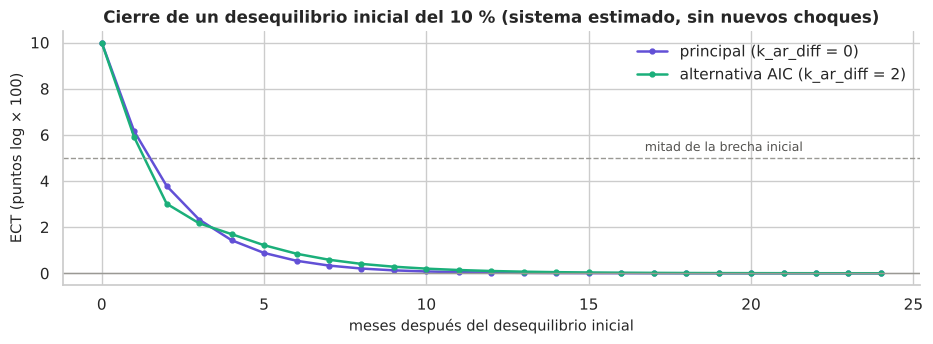

In [19]:
def trayectoria_desequilibrio(res, brecha=0.10, periodos=24):
    # Simula el VECM ('ci') sin choques: equilibrio + brecha en la primera variable; cambios pasados nulos
    a, b, m0 = res.alpha, res.beta, res.det_coef_coint[0, 0]
    k_, p_ = a.shape[0], res.k_ar - 1
    nivel = np.array([-(m0 + b[1, 0] * 1.0), 1.0]) + np.array([brecha, 0.0])
    difs = [np.zeros(k_) for _ in range(p_)]
    camino = [float(b[:, 0] @ nivel + m0)]
    for _ in range(periodos):
        d = (a @ (b.T @ nivel + m0)).ravel()
        for i in range(p_):
            d = d + res.gamma[:, i * k_:(i + 1) * k_] @ difs[i]
        nivel = nivel + d
        difs = ([d] + difs[:-1]) if p_ > 0 else difs
        camino.append(float(b[:, 0] @ nivel + m0))
    return np.array(camino)

def semivida(camino):
    debajo = np.abs(camino) <= 0.5 * abs(camino[0])
    return int(np.argmax(debajo)) if debajo.any() else np.nan

cam0, cam_aic = trayectoria_desequilibrio(vecm_res), trayectoria_desequilibrio(res_aic)
print(f"Modelo principal: fórmula AR(1) = {np.log(0.5) / np.log(1 + beta_alpha):.2f} meses | "
      f"simulación: la brecha baja a la mitad en el mes {semivida(cam0)}")
ba_aic = (res_aic.beta.T @ res_aic.alpha).item()
print(f"Modelo AIC     : fórmula AR(1) (NO válida aquí) = {np.log(0.5) / np.log(1 + ba_aic):.2f} meses | "
      f"simulación: mes {semivida(cam_aic)}")

display(pd.DataFrame({"principal (k_ar_diff = 0)": cam0[:7] / cam0[0], f"AIC (k_ar_diff = {int(sel.aic)})": cam_aic[:7] / cam_aic[0]},
                     index=pd.Index(range(7), name="mes")).T.round(3).rename(columns=lambda h: f"mes {h}"))

fig, ax = plt.subplots(figsize=(9.5, 3.6))
ax.plot(100 * cam0, marker="o", ms=3.5, color=COL["ECT"], label="principal (k_ar_diff = 0)")
ax.plot(100 * cam_aic, marker="o", ms=3.5, color=COL["VAR_niv"], label=f"alternativa AIC (k_ar_diff = {int(sel.aic)})")
ax.axhline(5, color=COL["ref"], ls="--", lw=1); ax.axhline(0, color=COL["ref"], lw=1)
ax.annotate("mitad de la brecha inicial", (24, 5), xytext=(-170, 5), textcoords="offset points", fontsize=9, color="#52514e")
ax.set_xlabel("meses después del desequilibrio inicial"); ax.set_ylabel("ECT (puntos log × 100)")
ax.set_title("Cierre de un desequilibrio inicial del 10 % (sistema estimado, sin nuevos choques)"); ax.legend()
plt.tight_layout(); plt.show()

**Interpretación.** En el modelo principal la fórmula y la simulación son la misma cosa: la fracción remanente se multiplica
por ≈ 0.615 cada mes (0.615, 0.378, 0.233…), y la semivida es ≈ 1.4 meses. En el modelo con dos rezagos la trayectoria
**no es geométrica**: la brecha cae más rápido en los dos primeros meses y más despacio después, de modo que a partir del
cuarto mes conserva más desequilibrio que el modelo principal. Ningún número único la resume bien, y la fórmula simple
(1.31 meses) no describe ese patrón. Ambas especificaciones coinciden en lo esencial: los desequilibrios entre crudo y
gasóleo se corrigen casi por completo en menos de un año, y la mayor parte en los primeros meses.

### 7.6 Dinámica de corto plazo ($\Gamma$) y causalidad de Granger

La especificación principal no tiene $\Gamma$. Para que el estudiante sepa leerlas, las mostramos para la alternativa de AIC.

In [20]:
nombres_g = [f"Δ{c} (t−{l})" for l in range(1, int(sel.aic) + 1) for c in datos.columns]
gam = pd.DataFrame(res_aic.gamma, index=["ec. Δln_CL", "ec. Δln_HO"], columns=nombres_g)
pg = pd.DataFrame(res_aic.pvalues_gamma, index=gam.index, columns=nombres_g)
display(pd.concat({"coef": gam, "p-valor": pg}).round(3))
print(f"Modelo AIC: β₂ = {res_aic.beta[1, 0]:.3f}; α = {np.round(res_aic.alpha[:, 0], 3)}; "
      f"p-valores de α = {np.round(res_aic.pvalues_alpha[:, 0], 3)}")

print("\nCausalidad de Granger dentro del VECM principal:")
for causante, causada in ((0, 1), (1, 0)):
    g = vecm_res.test_granger_causality(caused=causada, causing=causante)
    print(f"   {ETIQ[datos.columns[causante]]} → {ETIQ[datos.columns[causada]]}: p-valor = {g.pvalue:.4f}")

Δln_CL (t−1)  Δln_HO (t−1)  Δln_CL (t−2)  Δln_HO (t−2)
coef    ec. Δln_CL         0.341        -0.109        -0.420         0.426
        ec. Δln_HO         0.255        -0.073        -0.315         0.271
p-valor ec. Δln_CL         0.027         0.521         0.006         0.005
        ec. Δln_HO         0.054         0.614         0.015         0.038

Modelo AIC: β₂ = -0.813; α = [-0.293  0.144]; p-valores de α = [0.054 0.27 ]

Causalidad de Granger dentro del VECM principal:
   ln(crudo WTI) → ln(gasóleo): p-valor = 0.0004
   ln(gasóleo) → ln(crudo WTI): p-valor = 0.9647


**Cómo leer $\Gamma$.** Cada fila es una ecuación y cada columna un cambio rezagado. El coeficiente de la fila
"ec. Δln_CL" y la columna "Δln_CL (t−1)" mide cuánto del cambio del crudo del mes pasado persiste en el de este mes
**manteniendo constante el desequilibrio**. En la ecuación del crudo, el primer rezago propio es positivo y significativo, y
en el segundo rezago aparecen coeficientes de signo opuesto y magnitud parecida para crudo y gasóleo, un patrón que
reacciona a cambios pasados del diferencial. BIC no los incluye porque la mejora de ajuste no compensa los 8 parámetros
adicionales con $T=120$.

Note que con dos rezagos $\hat\beta_2$ casi no cambia, pero **$\hat\alpha$ sí**: ahora es el crudo el que parece ajustar
(p ≈ 0.05, en el límite) y el gasóleo deja de ser significativo. La pregunta "¿qué precio corrige?" es sensible a la especificación; el Módulo 8 lo
documenta.

**Granger.** Dentro del VECM principal, se rechaza que el crudo no anticipe al gasóleo (p < 0.001) y no se rechaza en el
sentido contrario. Sin $\Gamma$, la única vía por la que el pasado de una variable influye en la otra es el ECT, así que el
resultado es coherente con los $\alpha$. **Causalidad de Granger es precedencia predictiva, no causalidad económica.**

**Efecto de corto y de largo plazo.** En la forma reducida del modelo principal, el gasóleo no entra de forma
contemporánea en la ecuación del crudo ni con rezagos en diferencias (no hay $\Gamma$): su único canal es el ECT. Si el
gasóleo sube un 1 % de forma permanente, la relación de equilibrio dice que, una vez cerrada la brecha, el crudo
compatible con él es 0.845 % más alto. Las respuestas a impulsos del Módulo 9 muestran el
camino entre ambos.

> **Actividad 7.3.** Con el modelo de dos rezagos, ¿puede afirmarse que "el gasóleo corrige el 24.8 % del desequilibrio
> cada mes"? Señale los dos errores que contiene esa frase.

---
## Módulo 8. Diagnóstico y validación

**¿Qué problema resolvemos?** Saber si podemos confiar en las conclusiones del Módulo 7. **¿Por qué?** La validez de la
prueba de Johansen y de los errores estándar depende, sobre todo, de que los residuos no tengan autocorrelación; las
conclusiones económicas dependen, además, de que no cambien con decisiones razonables del analista. **¿Qué calculamos?**
Distinguimos dos tipos de evidencia:

| Tipo | Qué es | En este módulo |
|---|---|---|
| **Pruebas formales** | Contrastes con hipótesis nula y distribución conocida (al menos asintóticamente) | Portmanteau, Ljung-Box, Jarque-Bera, ARCH-LM, LR de cambio estructural |
| **Comprobaciones exploratorias** | Gráficos y cálculos que orientan pero no contrastan una hipótesis | Residuos, gráfico Q-Q, observaciones extremas, raíces, estimación recursiva, sensibilidad |

**¿Cómo lo interpretaremos?** La ausencia de autocorrelación es la condición crítica. La no normalidad y la
heterocedasticidad no sesgan $\hat\beta$, pero afectan la eficiencia, la validez exacta de los intervalos de pronóstico
gaussianos y, en muestras pequeñas, el tamaño de la prueba de Johansen.

### 8.1 Pruebas formales sobre los residuos

In [21]:
idx_res = datos.index[K_AR_DIFF + 1:]                 # el VECM pierde k_ar_diff + 1 observaciones iniciales
residuos = pd.DataFrame(vecm_res.resid, index=idx_res, columns=datos.columns)
assert len(residuos) == vecm_res.nobs
z = (residuos - residuos.mean()) / residuos.std()

diag = []
w = vecm_res.test_whiteness(nlags=12, adjusted=True)
diag.append({"Prueba": "Portmanteau multivariada (12 rezagos, ajustada)", "H0": "sin autocorrelación conjunta",
             "Estadístico": w.test_statistic, "p-valor": w.pvalue})
for c in datos.columns:
    lb = acorr_ljungbox(residuos[c], lags=[12])
    diag.append({"Prueba": f"Ljung-Box (12) — {c}", "H0": "sin autocorrelación",
                 "Estadístico": lb["lb_stat"].iloc[0], "p-valor": lb["lb_pvalue"].iloc[0]})
nrm = vecm_res.test_normality()
diag.append({"Prueba": "Jarque-Bera multivariada", "H0": "normalidad conjunta", "Estadístico": nrm.test_statistic, "p-valor": nrm.pvalue})
for c in datos.columns:
    lm, p_lm, _, _ = het_arch(residuos[c], nlags=6)
    diag.append({"Prueba": f"ARCH-LM (6) — {c}", "H0": "varianza condicional constante", "Estadístico": lm, "p-valor": p_lm})
tabla_diag = pd.DataFrame(diag)
tabla_diag["Decisión 5%"] = np.where(tabla_diag["p-valor"] < 0.05, "rechaza H0", "no rechaza H0")
display(tabla_diag.round(4))
print("Asimetría y curtosis (exceso) de los residuos:")
display(pd.DataFrame({"asimetría": residuos.skew(), "curtosis (exceso)": residuos.kurt()}).round(2))
print("Observaciones con |residuo estandarizado| > 3:")
display(z[(z.abs() > 3).any(axis=1)].round(2))

,Prueba,H0,Estadístico,p-valor,Decisión 5%
0,"Portmanteau multivariada (12 rezagos, ajustada)",sin autocorrelación conjunta,45.2164,0.5050,no rechaza H0
1,Ljung-Box (12) — ln_CL,sin autocorrelación,14.1636,0.2904,no rechaza H0
2,Ljung-Box (12) — ln_HO,sin autocorrelación,15.6033,0.2101,no rechaza H0
3,Jarque-Bera multivariada,normalidad conjunta,1126.4159,0.0000,rechaza H0
4,ARCH-LM (6) — ln_CL,varianza condicional constante,26.7961,0.0002,rechaza H0
5,ARCH-LM (6) — ln_HO,varianza condicional constante,18.9554,0.0042,rechaza H0


Asimetría y curtosis (exceso) de los residuos:


,asimetría,curtosis (exceso)
ln_CL,-1.32,14.06
ln_HO,0.13,1.33


Observaciones con |residuo estandarizado| > 3:


,ln_CL,ln_HO
fecha,,
2020-03-31,-6.15,-3.34
2020-05-31,4.47,3.09


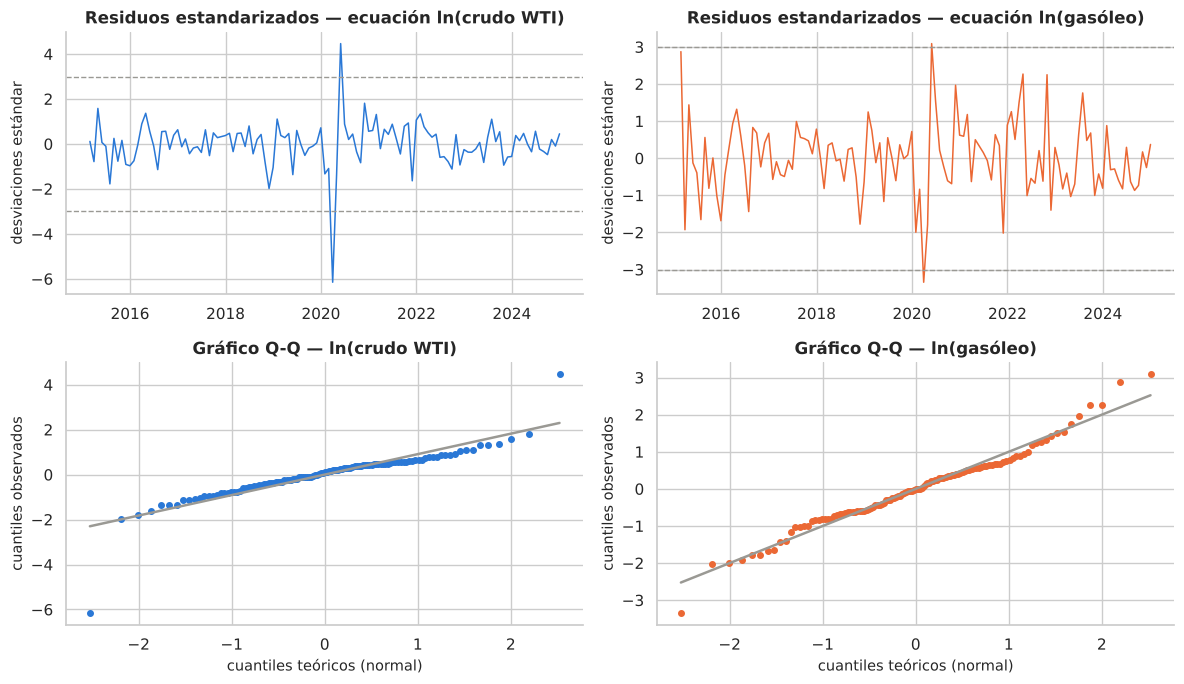

In [22]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for j, c in enumerate(datos.columns):
    color = COL[c[-2:]]
    axes[0, j].plot(z.index, z[c], color=color, lw=1.1)
    for lim in (-3, 3):
        axes[0, j].axhline(lim, color=COL["ref"], ls="--", lw=1)
    axes[0, j].set_title(f"Residuos estandarizados — ecuación {ETIQ[c]}")
    axes[0, j].set_ylabel("desviaciones estándar"); eje_fechas(axes[0, j], 2)
    stats.probplot(z[c], dist="norm", plot=axes[1, j])
    axes[1, j].get_lines()[0].set(color=color, markersize=4)
    axes[1, j].get_lines()[1].set(color=COL["ref"])
    axes[1, j].set_title(f"Gráfico Q-Q — {ETIQ[c]}")
    axes[1, j].set_xlabel("cuantiles teóricos (normal)"); axes[1, j].set_ylabel("cuantiles observados")
plt.tight_layout(); plt.show()

**Interpretación.**

- **Autocorrelación (formal):** la prueba Portmanteau y Ljung-Box no rechazan la ausencia de autocorrelación. La condición
  crítica se cumple con `k_ar_diff = 0`.
- **Normalidad (formal):** se rechaza con fuerza. Los gráficos muestran por qué: colas pesadas dominadas por **marzo y mayo
  de 2020** (residuos de más de 3 desviaciones estándar en el crudo). La no normalidad no invalida $\hat\beta$, que sigue
  siendo consistente, pero los intervalos de pronóstico gaussianos serán demasiado estrechos en episodios extremos.
- **Heterocedasticidad condicional (formal):** ARCH-LM rechaza en ambas ecuaciones: la volatilidad se agrupa (2015-2016,
  2020, 2022). Los errores estándar de $\hat\alpha$ deben leerse con cautela.

### 8.2 Estabilidad dinámica (comprobación exploratoria)

Un VECM con $k=2$ y $r=1$ implica un VAR en niveles con **exactamente $k-r=1$ raíz unitaria** y las demás dentro del círculo
unitario. Con `k_ar_diff = 0`, las raíces deben ser $1$ y $1+\beta'\alpha$.

In [23]:
A = vecm_res.var_rep                       # (p, k, k): VAR en niveles implícito
p_var, k_var = A.shape[0], A.shape[1]
companion = np.zeros((k_var * p_var, k_var * p_var))
companion[:k_var, :] = np.hstack(list(A))
if p_var > 1:
    companion[k_var:, :-k_var] = np.eye(k_var * (p_var - 1))
print("Módulos de los autovalores de la matriz compañera:", np.round(np.sort(np.abs(np.linalg.eigvals(companion)))[::-1], 4))
print(f"Esperado con k_ar_diff = 0: 1 y 1 + β'α = {1 + beta_alpha:.4f}")

Módulos de los autovalores de la matriz compañera: [1.     0.6152]
Esperado con k_ar_diff = 0: 1 y 1 + β'α = 0.6152


Los módulos son 1 (la tendencia común) y ≈ 0.61 (la persistencia del desequilibrio): el sistema es dinámicamente
estable en el sentido que exige un VECM con una relación de cointegración.

### 8.3 Cambio estructural

**Exploratorio: estimación recursiva.** Reestimamos el modelo con muestras que terminan entre 2018 y 2024 y observamos si
$\hat\beta_2$ y $\hat\alpha$ se desplazan.

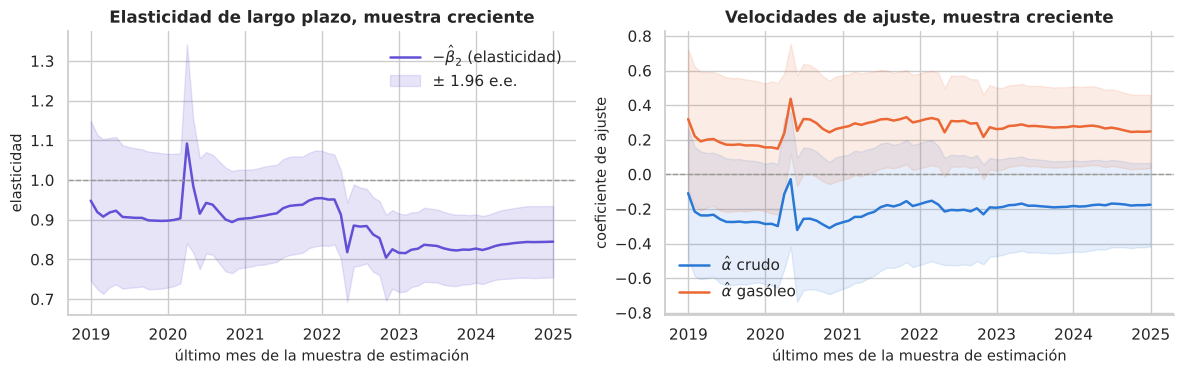

In [24]:
recursivo = []
for fin in datos.loc["2018-12":].index:
    r_ = VECM(datos.loc[:fin], k_ar_diff=K_AR_DIFF, coint_rank=1, deterministic=DETERMINISTICO).fit()
    recursivo.append({"fin": fin, "elast": -r_.beta[1, 0], "se_b": r_.stderr_beta[1, 0],
                      "a_CL": r_.alpha[0, 0], "se_aCL": r_.stderr_alpha[0, 0],
                      "a_HO": r_.alpha[1, 0], "se_aHO": r_.stderr_alpha[1, 0]})
recursivo = pd.DataFrame(recursivo).set_index("fin")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.9))
axes[0].plot(recursivo.index, recursivo["elast"], color=COL["ECT"], label=r"$-\hat\beta_2$ (elasticidad)")
axes[0].fill_between(recursivo.index, recursivo["elast"] - 1.96 * recursivo["se_b"], recursivo["elast"] + 1.96 * recursivo["se_b"],
                     color=COL["ECT"], alpha=0.15, label="± 1.96 e.e.")
axes[0].axhline(1, color=COL["ref"], ls="--", lw=1)
axes[0].set_title("Elasticidad de largo plazo, muestra creciente"); axes[0].set_ylabel("elasticidad")
axes[0].legend(loc="upper right")
for nombre, se, c, etq in (("a_CL", "se_aCL", COL["CL"], r"$\hat\alpha$ crudo"), ("a_HO", "se_aHO", COL["HO"], r"$\hat\alpha$ gasóleo")):
    axes[1].plot(recursivo.index, recursivo[nombre], color=c, label=etq)
    axes[1].fill_between(recursivo.index, recursivo[nombre] - 1.96 * recursivo[se], recursivo[nombre] + 1.96 * recursivo[se],
                         color=c, alpha=0.12)
axes[1].axhline(0, color=COL["ref"], ls="--", lw=1)
axes[1].set_title("Velocidades de ajuste, muestra creciente"); axes[1].set_ylabel("coeficiente de ajuste")
axes[1].legend(loc="lower left")
for ax in axes:
    ax.set_xlabel("último mes de la muestra de estimación"); eje_fechas(ax)
plt.tight_layout(); plt.show()

**Formal: prueba de razón de verosimilitudes para un cambio de nivel en el equilibrio.** Añadimos a la relación de
cointegración una variable escalón $S_t = 1\{t \ge t_0\}$ (argumento `exog_coint`) y comparamos la verosimilitud con la del
modelo principal. Con el rango fijado, las restricciones sobre la relación de cointegración se contrastan con una
$\chi^2$ asintótica con un grado de libertad. Las fechas se fijan **antes** de mirar el resultado, por razones económicas:
marzo de 2020 (pandemia) y marzo de 2022 (invasión de Ucrania). Si se buscara la fecha que maximiza el estadístico, la
$\chi^2$ dejaría de ser válida.

In [25]:
filas = []
for fecha_q in ("2020-03-31", "2022-03-31"):
    escalon = pd.DataFrame({"escalon": (datos.index >= fecha_q).astype(float)}, index=datos.index)
    r_q = VECM(datos, k_ar_diff=K_AR_DIFF, coint_rank=1, deterministic=DETERMINISTICO, exog_coint=escalon).fit()
    lr = 2 * (np.real(r_q.llf) - np.real(vecm_res.llf))
    filas.append({"fecha del quiebre": fecha_q[:7], "LR": lr, "p-valor χ²(1)": stats.chi2.sf(lr, 1),
                  "β₂ con escalón": r_q.beta[1, 0], "coef. del escalón": r_q.det_coef_coint[1, 0]})
display(pd.DataFrame(filas).set_index("fecha del quiebre").round(4))

,LR,p-valor χ²(1),β₂ con escalón,coef. del escalón
fecha del quiebre,,,,
2020-03,2.0152,0.1557,-0.7967,-0.0549
2022-03,0.0022,0.9625,-0.8471,0.0024


**Interpretación.**

- **Exploratorio:** la elasticidad recursiva se mueve entre ≈ 0.80 y ≈ 0.95, con un salto puntual al incorporar marzo de 2020.
  Hasta 2021 la banda incluye el 1; solo al añadir 2022 la elasticidad baja a ≈ 0.82-0.85 y la banda excluye el 1. La banda
  de $\hat\alpha$ del crudo incluye el cero con cualquier muestra; la del gasóleo lo excluye en casi todas las muestras que
  terminan después de abril de 2021, pero no en las anteriores.
- **Formal:** un cambio de nivel en el equilibrio en marzo de 2020 o en marzo de 2022 **no** resulta significativo.
- **Lectura conjunta:** no hay evidencia formal de un desplazamiento del nivel del equilibrio en esas fechas, pero las
  estimaciones recursivas muestran que la homogeneidad y "quién ajusta" dependen del período. Son conclusiones a reportar
  con cautela. (Una prueba sin fecha conocida, como Gregory-Hansen, no está disponible en `statsmodels`.)

### 8.4 Sensibilidad a rezagos, términos deterministas y observaciones extremas

In [26]:
ficticias = pd.DataFrame(0.0, index=datos.index, columns=["d2020_03", "d2020_04", "d2020_05"])
for col, f in zip(ficticias.columns, ["2020-03-31", "2020-04-30", "2020-05-31"]):
    ficticias.loc[f, col] = 1.0

filas = []
for kd in (0, 1, 2):
    for det in ("ci", "co"):
        for con_d in (False, True):
            r_ = VECM(datos, exog=ficticias if con_d else None, k_ar_diff=kd, coint_rank=1, deterministic=det).fit()
            filas.append({"k_ar_diff": kd, "determ.": det, "ficticias 2020": "sí" if con_d else "no",
                          "elasticidad −β₂": -r_.beta[1, 0],
                          "α crudo": r_.alpha[0, 0], "p α crudo": r_.pvalues_alpha[0, 0],
                          "α gasóleo": r_.alpha[1, 0], "p α gasóleo": r_.pvalues_alpha[1, 0],
                          "β'α": (r_.beta.T @ r_.alpha).item(),
                          "p Portmanteau": r_.test_whiteness(nlags=12, adjusted=True).pvalue,
                          "p normalidad": r_.test_normality().pvalue})
sens_vecm = pd.DataFrame(filas)
display(sens_vecm.round(3))

,k_ar_diff,determ.,ficticias 2020,elasticidad −β₂,α crudo,p α crudo,α gasóleo,p α gasóleo,β'α,p Portmanteau,p normalidad
0,0,ci,no,0.845,-0.175,0.155,0.248,0.022,-0.385,0.505,0.0
1,0,ci,sí,0.845,-0.101,0.339,0.234,0.047,-0.299,0.783,0.0
2,0,co,no,0.845,-0.175,0.155,0.248,0.022,-0.385,0.503,0.0
3,0,co,sí,0.844,-0.104,0.323,0.231,0.050,-0.299,0.777,0.0
4,1,ci,no,0.819,-0.389,0.004,0.103,0.376,-0.473,0.598,0.0
5,1,ci,sí,0.819,-0.158,0.167,0.202,0.102,-0.324,0.747,0.0
6,1,co,no,0.819,-0.389,0.004,0.103,0.376,-0.473,0.597,0.0
7,1,co,sí,0.819,-0.155,0.178,0.206,0.096,-0.324,0.742,0.0
8,2,ci,no,0.813,-0.293,0.054,0.144,0.270,-0.410,0.862,0.0
9,2,ci,sí,0.809,-0.184,0.137,0.139,0.291,-0.297,0.777,0.0


**Lectura.**

- **$\beta$ es robusto:** la elasticidad se mueve entre ≈ 0.81 y ≈ 0.85 en todas las variantes; `"ci"` y `"co"` dan
  prácticamente lo mismo, y las ficticias de 2020 tampoco la alteran.
- **$\alpha$ no es robusto:** con 0 rezagos ajusta el gasóleo; con 1 rezago ajusta el crudo y el gasóleo deja de ser
  significativo; con 2 rezagos ninguno es claramente significativo al 5 %. En todas las variantes $\beta'\alpha<0$: **el
  sistema corrige**, aunque no se pueda atribuir con seguridad la corrección a uno de los mercados.
- **Autocorrelación:** no se detecta en ninguna variante. **Normalidad:** se rechaza incluso con las ficticias.

### 8.5 Coherencia económica de los resultados

| Comprobación | Resultado | ¿Coherente? |
|---|---|---|
| Signo de la elasticidad de largo plazo | Positiva (≈ 0.85) | Sí: costo e insumo se mueven en la misma dirección |
| Magnitud de la elasticidad | Cercana a 1, algo menor | Plausible; la homogeneidad estricta depende del período |
| Corrección del sistema ($\beta'\alpha$) | Negativa en todas las variantes | Sí: los desequilibrios se cierran |
| Velocidad (semivida) | ≈ 1.4 meses | Plausible para mercados de futuros líquidos |
| Quién ajusta | Depende de los rezagos | Ambiguo: hallazgo tentativo |
| Raíces del sistema | 1 y ≈ 0.61 | Sí: una tendencia común, sistema estable |

### 8.6 Resumen del diagnóstico

| Aspecto | Hallazgo | Implicación | Respuesta posible |
|---|---|---|---|
| Autocorrelación residual | No detectada | `k_ar_diff = 0` es aceptable | — |
| Normalidad | Rechazada (colas pesadas, 2020) | Intervalos gaussianos poco fiables | *Bootstrap*, ficticias |
| Heterocedasticidad (ARCH) | Presente | Errores estándar de $\alpha$ con cautela | Errores robustos, modelos de volatilidad |
| Cambio de nivel 2020/2022 | No significativo | El equilibrio no se desplazó en esas fechas | — |
| Estabilidad de $\beta$ y $\alpha$ | $\beta$ razonable; $\alpha$ baja | "Quién ajusta" es tentativo | Reportar como tal |

> **Actividad 8.1.** ¿Por qué la ausencia de autocorrelación residual es más importante que la normalidad para confiar en la
> prueba de Johansen y en los errores estándar? ¿Por qué tiene sentido que $\hat\beta$ sea más estable que $\hat\alpha$?

---
## Módulo 9. Respuestas a impulsos

**¿Qué problema resolvemos?** Ver cómo se propaga en el tiempo un choque inesperado en uno de los precios. **¿Por qué?**
Los coeficientes $\alpha$, $\beta$ y $\Gamma$ actúan a la vez; la función impulso-respuesta (IRF) resume su efecto conjunto.
**¿Qué calculamos?** La diferencia entre la trayectoria esperada de cada variable con y sin un choque en el mes 0, para
24 meses, con intervalos de confianza por *bootstrap*. **¿Cómo lo interpretaremos?** Distinguiendo el efecto de impacto,
la transición y el efecto de largo plazo.

### 9.1 Identificación

- **IRF no ortogonalizadas:** choque de una unidad en $\varepsilon_j$ con los demás errores en cero. Como los errores están
  muy correlacionados, ese experimento es poco realista.
- **IRF ortogonalizadas (Cholesky):** se descompone $\boldsymbol\Sigma = \mathbf P\mathbf P'$ ($\mathbf P$ triangular inferior)
  y se usan choques no correlacionados $\mathbf u_t = \mathbf P^{-1}\boldsymbol\varepsilon_t$. La primera variable del orden
  puede afectar a todas en el mismo mes; la segunda no afecta a la primera en $h=0$. **El orden es un supuesto de
  identificación.** Ponemos primero el crudo (mercado global e insumo) y luego el gasóleo, y revisamos qué cambia al invertirlo.

En un sistema $I(1)$ cointegrado los choques tienen **efectos permanentes** sobre los niveles; lo que se desvanece es su
efecto sobre el desequilibrio: a largo plazo, $\beta'\,\mathbf{IRF}(\infty) = 0$.

### 9.2 Intervalos de confianza

`statsmodels` calcula `vecm_res.irf()`, pero **no ofrece errores estándar ni bandas para las IRF de un VECM** (sí para un
VAR). Los construimos con un *bootstrap* de residuos de diseño recursivo:

1. Se toman los residuos del VECM estimado, centrados.
2. Se generan $B$ series artificiales con los parámetros estimados ($\hat\alpha$, $\hat\beta$, $\hat\mu_0$), partiendo de la primera
   observación real y remuestreando residuos con reemplazo.
3. En cada serie se reestima el VECM (mismo rango, rezagos y términos deterministas) y se calculan las IRF.
4. Las bandas son los percentiles 5 y 95 de las IRF simuladas (intervalo del 90 %).

**Limitaciones:** las bandas de percentiles pueden tener cobertura imperfecta en muestras pequeñas (Kilian, 1998, propone
correcciones de sesgo); el remuestreo i.i.d. no reproduce la heterocedasticidad condicional detectada; y el rango y los
rezagos se mantienen fijos, de modo que no se refleja la incertidumbre sobre la especificación.

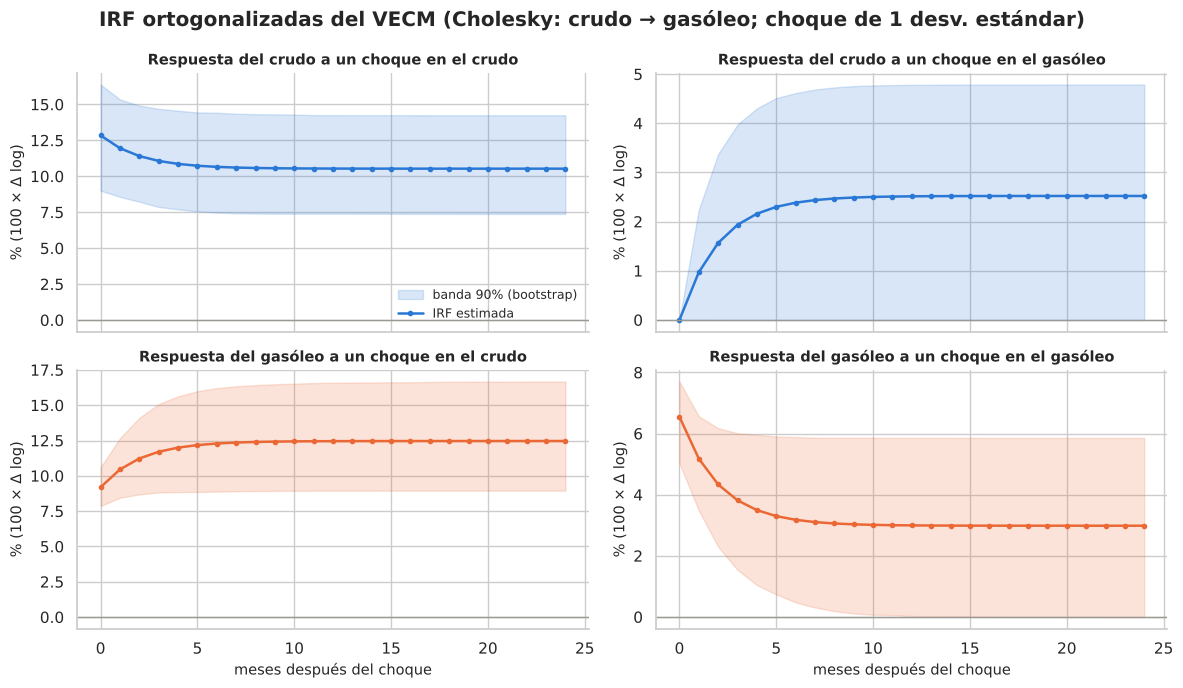

Respuestas en % con banda del 90 %:


,h=0,h=1,h=6,h=24
crudo ← choque crudo,12.8 [9.0; 16.4],12.0 [8.6; 15.3],10.7 [7.5; 14.4],10.5 [7.4; 14.2]
gasóleo ← choque crudo,9.2 [7.9; 10.6],10.5 [8.4; 12.7],12.3 [8.9; 16.2],12.5 [8.9; 16.7]
crudo ← choque gasóleo,0.0 [0.0; 0.0],1.0 [-0.0; 2.2],2.4 [-0.0; 4.6],2.5 [-0.0; 4.8]
gasóleo ← choque gasóleo,6.5 [5.0; 7.7],5.2 [3.5; 6.6],3.2 [0.5; 5.9],3.0 [-0.0; 5.9]


β' · IRF no ortogonalizada en h = 24 (debe ser ≈ 0): [[ 1.e-05 -1.e-05]]
Cociente de respuestas de largo plazo gasóleo/crudo ante choque al crudo: 1.184 (1/elasticidad = 1.184)


In [27]:
H_IRF = 24
B_BOOT = 999
irf_vecm = vecm_res.irf(periods=H_IRF)
oirf = irf_vecm.orth_irfs                       # (H+1, respuesta, choque)

def bootstrap_irf(res, datos_m, H, B, semilla=SEMILLA):
    # Bootstrap de residuos (diseño recursivo) para un VECM con k_ar_diff = 0 y constante restringida
    assert res.k_ar == 1 and res.deterministic == "ci", "Implementado para la especificación principal"
    rng_b = np.random.default_rng(semilla)
    a, b, m0 = res.alpha, res.beta, res.det_coef_coint[0, 0]
    e = res.resid - res.resid.mean(axis=0)
    T_, k_ = datos_m.shape
    salida = np.empty((B, H + 1, k_, k_))
    for i in range(B):
        e_b = e[rng_b.integers(0, len(e), T_ - 1)]
        Yb = np.empty((T_, k_)); Yb[0] = datos_m.values[0]
        for t in range(1, T_):
            Yb[t] = Yb[t - 1] + (a @ (b.T @ Yb[t - 1] + m0)).ravel() + e_b[t - 1]
        rb = VECM(pd.DataFrame(Yb, columns=datos_m.columns), k_ar_diff=0, coint_rank=1, deterministic="ci").fit()
        salida[i] = rb.irf(periods=H).orth_irfs
    return salida

boot = bootstrap_irf(vecm_res, datos, H_IRF, B_BOOT)
banda_inf, banda_sup = np.percentile(boot, [5, 95], axis=0)

horiz = np.arange(H_IRF + 1)
corto = {"ln_CL": "crudo", "ln_HO": "gasóleo"}
cols = list(datos.columns)
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
for i, resp in enumerate(cols):
    for j, choque in enumerate(cols):
        ax = axes[i, j]
        color = COL[resp[-2:]]
        ax.fill_between(horiz, 100 * banda_inf[:, i, j], 100 * banda_sup[:, i, j], color=color, alpha=0.18, label="banda 90% (bootstrap)")
        ax.plot(horiz, 100 * oirf[:, i, j], color=color, marker="o", ms=3, label="IRF estimada")
        ax.axhline(0, color=COL["ref"], lw=1)
        ax.set_title(f"Respuesta del {corto[resp]} a un choque en el {corto[choque]}", fontsize=10.5)
        ax.set_ylabel("% (100 × Δ log)")
axes[1, 0].set_xlabel("meses después del choque"); axes[1, 1].set_xlabel("meses después del choque")
axes[0, 0].legend(loc="lower right", fontsize=9)
fig.suptitle("IRF ortogonalizadas del VECM (Cholesky: crudo → gasóleo; choque de 1 desv. estándar)", fontweight="bold")
plt.tight_layout(); plt.show()

resumen_irf = pd.DataFrame({f"h={h}": [f"{100 * oirf[h, i, j]:.1f} [{100 * banda_inf[h, i, j]:.1f}; {100 * banda_sup[h, i, j]:.1f}]"
                                        for i, j in ((0, 0), (1, 0), (0, 1), (1, 1))] for h in (0, 1, 6, 24)},
                           index=["crudo ← choque crudo", "gasóleo ← choque crudo", "crudo ← choque gasóleo", "gasóleo ← choque gasóleo"])
print("Respuestas en % con banda del 90 %:")
display(resumen_irf)
print("β' · IRF no ortogonalizada en h = 24 (debe ser ≈ 0):", np.round(vecm_res.beta.T @ irf_vecm.irfs[-1], 5))
print(f"Cociente de respuestas de largo plazo gasóleo/crudo ante choque al crudo: {oirf[-1, 1, 0] / oirf[-1, 0, 0]:.3f} "
      f"(1/elasticidad = {1 / -b2:.3f})")

**Interpretación.**

- **Choque en el crudo (columna izquierda).** Un choque de una desviación estándar eleva el crudo ≈ 12.8 % en el impacto y
  el gasóleo ≈ 9.2 % ese mismo mes (por la correlación contemporánea que asigna Cholesky). Luego el crudo retrocede un
  poco y el gasóleo sigue subiendo, hasta estabilizarse en pocos meses: ≈ +10.5 % el crudo y ≈ +12.5 % el gasóleo. Las
  bandas no incluyen el cero: **el efecto es permanente y estadísticamente distinto de cero**.
- **Choque en el gasóleo (columna derecha).** Por construcción no mueve al crudo en $h=0$. Su efecto permanente sobre el
  gasóleo es pequeño (≈ 3 %) y su banda llega al cero en el horizonte largo; sobre el crudo, la banda incluye el cero en
  todos los horizontes posteriores al impacto (en $h=0$ la respuesta es cero por construcción). La mayor parte de un choque propio del gasóleo es transitoria.
- **Corto frente a largo plazo (ejemplo numérico).** Ante el choque al crudo, el gasóleo sube 9.2 % en el impacto y 12.5 %
  a largo plazo; el crudo, 12.8 % y 10.5 %. El cociente de largo plazo, 12.5/10.5 ≈ 1.18, coincide con $1/0.845$: tras el
  choque, los precios se reacomodan hasta respetar la relación de equilibrio, y $\hat\beta'\,\mathrm{IRF}(24)\approx 0$ lo
  confirma.
- **Horizonte.** La transición se completa en 3-6 meses, coherente con la semivida de ≈ 1.4 meses.

### 9.3 ¿Cuánto depende del orden de Cholesky?

In [28]:
res_inv = VECM(datos[["ln_HO", "ln_CL"]], k_ar_diff=K_AR_DIFF, coint_rank=1, deterministic=DETERMINISTICO).fit()
oirf_inv = res_inv.irf(periods=H_IRF).orth_irfs      # orden: gasóleo → crudo
print(f"Correlación entre los residuos de las dos ecuaciones: {np.corrcoef(vecm_res.resid.T)[0, 1]:.3f}")
display(pd.DataFrame({
    "orden crudo → gasóleo": [100 * oirf[0, 1, 0], 100 * oirf[-1, 1, 0], 100 * oirf[0, 0, 1], 100 * oirf[-1, 0, 1]],
    "orden gasóleo → crudo": [100 * oirf_inv[0, 0, 1], 100 * oirf_inv[-1, 0, 1], 100 * oirf_inv[0, 1, 0], 100 * oirf_inv[-1, 1, 0]],
}, index=["gasóleo ← choque crudo (h=0)", "gasóleo ← choque crudo (h=24)",
          "crudo ← choque gasóleo (h=0)", "crudo ← choque gasóleo (h=24)"]).round(2))

Correlación entre los residuos de las dos ecuaciones: 0.814


,orden crudo → gasóleo,orden gasóleo → crudo
gasóleo ← choque crudo (h=0),9.19,0.00
gasóleo ← choque crudo (h=24),12.46,4.80
crudo ← choque gasóleo (h=0),0.00,10.46
crudo ← choque gasóleo (h=24),2.52,10.04


**Interpretación.** Con una correlación contemporánea de ≈ 0.81 entre los errores, el orden pesa mucho: con el gasóleo
primero, un choque en el gasóleo mueve al crudo de inmediato y con efecto permanente grande, y el "choque del crudo" queda
reducido a la parte no explicada por el gasóleo. **Ambas versiones son matemáticamente válidas; cambia el supuesto de
identificación**, que debe justificarse con argumentos económicos. Ninguna es una prueba de causalidad.

### 9.4 Descomposición de la varianza del error de pronóstico (FEVD)

¿Qué proporción del error de pronóstico de cada variable a $h$ meses se debe a cada choque ortogonalizado? Con las
respuestas ortogonalizadas $\theta_{ij}(s)$: $\omega_{ij}(h) = \sum_{s=0}^{h-1}\theta_{ij}(s)^2 / \sum_m\sum_{s=0}^{h-1}\theta_{im}(s)^2$.
`statsmodels` no ofrece `fevd()` para VECM; la calculamos desde `orth_irfs` y verificamos la función contra un VAR, donde
`statsmodels` sí la implementa.

In [29]:
def fevd_desde_oirf(orth_irfs):
    acumulado = np.cumsum(orth_irfs ** 2, axis=0)
    return acumulado / acumulado.sum(axis=2, keepdims=True)

var_chk = VAR(datos).fit(1)
print("¿Coincide con statsmodels en un VAR?",
      np.allclose(np.transpose(var_chk.fevd(H_IRF).decomp, (1, 0, 2)), fevd_desde_oirf(var_chk.irf(H_IRF).orth_irfs)[:H_IRF]))
fevd_vecm = fevd_desde_oirf(oirf)
display(pd.DataFrame({f"h={h}": [100 * fevd_vecm[h - 1, 0, 0], 100 * fevd_vecm[h - 1, 1, 0]] for h in (1, 3, 6, 12, 24)},
                     index=["% var. del crudo por choque del crudo", "% var. del gasóleo por choque del crudo"]).round(1))

¿Coincide con statsmodels en un VAR? True


,h=1,h=3,h=6,h=12,h=24
% var. del crudo por choque del crudo,100.0,99.2,97.9,96.5,95.6
% var. del gasóleo por choque del crudo,66.3,78.3,85.6,90.1,92.4


**Interpretación.** Con el orden crudo → gasóleo, los choques del crudo explican casi toda la varianza del error de
pronóstico del crudo y una proporción creciente de la del gasóleo: ≈ 66 % a un mes y más del 90 % a 12-24 meses. A
horizontes largos la incertidumbre de ambos precios la domina la tendencia común asociada al crudo. Esta conclusión hereda
el supuesto de orden de Cholesky.

> **Actividad 9.1 (después de las IRF).** ¿Cómo reacciona el sistema ante un choque en el crudo? Describa el efecto de
> impacto, la transición y el efecto de largo plazo, y explique por qué los efectos sobre los niveles no vuelven a cero.

---
## Módulo 10. Pronóstico y comparación de modelos

**¿Qué problema resolvemos?** Saber si el VECM pronostica mejor que alternativas más simples. **¿Por qué?** Un modelo puede
ser econométricamente adecuado y, aun así, no ser el mejor para pronosticar. **¿Qué calculamos?** Errores de pronóstico
fuera de muestra con origen móvil, a 1 y a varios meses, y pruebas de Diebold-Mariano. **¿Cómo lo interpretaremos?** Solo
consideraremos que un modelo es mejor si la diferencia es apreciable **y** estadísticamente distinguible.

### 10.1 Diseño

| Conjunto | Período | Uso |
|---|---|---|
| **Entrenamiento** | 2015-01 a 2021-12 (84 meses) | Estimación inicial |
| **Validación** | 2022-01 a 2023-06 (18 meses) | Elegir el número de rezagos de cada familia |
| **Prueba** | 2023-07 a 2024-12 (18 meses) | Evaluación final, una sola vez |

En cada mes de origen $t_0$ se reestima cada modelo con datos **hasta $t_0-1$** y se pronostican $h=1,\dots,6$ meses
(ventana expansiva). Solo se evalúan pronósticos cuyo objetivo cae dentro del período evaluado, de modo que ningún
pronóstico usa información posterior a su origen. Modelos (todos en logaritmos):

1. **VECM** con $r=1$ y constante restringida, `k_ar_diff` ∈ {0, 1, 2}.
2. **VAR en primeras diferencias** con $p$ ∈ {1, 2, 3} (coherente con $r=0$).
3. **VAR en niveles** con $p$ ∈ {1, 2, 3} (no impone ninguna restricción de rango).
4. **Ingenuo (paseo aleatorio):** el pronóstico es el último valor observado.

El rango $r=1$ se decidió con la muestra completa. Por eso el diseño incluye modelos coherentes con otros rangos y elige
los rezagos solo con la validación; ningún parámetro se estima con datos del período de prueba.

**Métricas.** El error se mide en puntos logarítmicos (0.10 ≈ 10 %). El **MAE** (error absoluto medio) pondera todos los
errores por igual y se lee como el error típico; el **RMSE** (raíz del error cuadrático medio) penaliza más los errores
grandes. Si el RMSE de un modelo es mucho mayor que su MAE, sus errores tienen episodios grandes.

In [30]:
FIN_TRAIN, INI_VAL, FIN_VAL = pd.Timestamp("2021-12-31"), pd.Timestamp("2022-01-31"), pd.Timestamp("2023-06-30")
INI_TEST, FIN_TEST = pd.Timestamp("2023-07-31"), datos.index[-1]
H_MAX = 6

def pronosticar(modelo, param, hist, h):
    # Pronósticos (h, 2) en logaritmos usando solo 'hist'
    if modelo == "VECM":
        return VECM(hist, k_ar_diff=param, coint_rank=1, deterministic=DETERMINISTICO).fit().predict(steps=h)
    if modelo == "VAR_dif":
        dh = hist.diff().dropna(); r = VAR(dh).fit(param, trend="c")
        return hist.values[-1] + np.cumsum(r.forecast(dh.values[-param:], h), axis=0)
    if modelo == "VAR_niv":
        r = VAR(hist).fit(param, trend="c"); return r.forecast(hist.values[-param:], h)
    if modelo == "Ingenuo":
        return np.repeat(hist.values[-1:], h, axis=0)
    raise ValueError(modelo)

def origen_movil(modelo, param, inicio, fin, h_max=H_MAX):
    filas, idx = [], datos.index
    for origen in idx[(idx >= inicio) & (idx <= fin)]:
        pos = idx.get_loc(origen)
        f = pronosticar(modelo, param, datos.iloc[:pos], h_max)    # información hasta el mes anterior al origen
        for h in range(h_max):
            if pos + h < len(idx) and idx[pos + h] <= fin:
                real = datos.iloc[pos + h].values
                filas.append({"modelo": modelo, "param": param, "origen": origen, "objetivo": idx[pos + h], "h": h + 1,
                              "pred_CL": f[h, 0], "pred_HO": f[h, 1], "e_CL": real[0] - f[h, 0], "e_HO": real[1] - f[h, 1]})
    return pd.DataFrame(filas)

CANDIDATOS = {"VECM": [0, 1, 2], "VAR_dif": [1, 2, 3], "VAR_niv": [1, 2, 3], "Ingenuo": [0]}
val = pd.concat([origen_movil(m, p, INI_VAL, FIN_VAL) for m, ps in CANDIDATOS.items() for p in ps], ignore_index=True)
val["ecm"] = (val["e_CL"] ** 2 + val["e_HO"] ** 2) / 2
rmse_val = val.groupby(["modelo", "param"])["ecm"].mean().pipe(np.sqrt).rename("RMSE validación (promedio 2 variables, h = 1..6)")
display(rmse_val.to_frame().round(4))
elegidos = rmse_val.groupby(level="modelo").idxmin().map(lambda t: t[1]).to_dict()
print("Configuración elegida en validación:", elegidos)

RMSE validación (promedio 2 variables, h = 1..6)
modelo  param                                                  
Ingenuo 0                                                0.2082
VAR_dif 1                                                0.2239
        2                                                0.2389
        3                                                0.2431
VAR_niv 1                                                0.2210
        2                                                0.2554
        3                                                0.2427
VECM    0                                                0.1983
        1                                                0.2555
        2                                                0.2419

Configuración elegida en validación: {'Ingenuo': 0, 'VAR_dif': 1, 'VAR_niv': 1, 'VECM': 0}


**Lectura de la validación.** Dentro de cada familia se elige la configuración con menor RMSE promedio. En este período
(2022-2023, con la volatilidad posterior a la invasión de Ucrania) el VECM con `k_ar_diff = 0` obtiene el menor error de
todos los candidatos, seguido del modelo ingenuo. Que gane en validación no garantiza que gane en prueba.

### 10.2 Evaluación final: un paso frente a varios pasos

Un paso (h = 1), puntos logarítmicos:


,MAE_crudo,RMSE_crudo,MAE_gasoleo,RMSE_gasoleo,n,RMSE prom. / ingenuo
modelo,,,,,,
Ingenuo,0.0577,0.0663,0.0666,0.0782,18,1.0000
VECM,0.0546,0.0650,0.0723,0.0834,18,1.0264
VAR_niv,0.0565,0.0678,0.0689,0.0825,18,1.0396
VAR_dif,0.0597,0.0686,0.0714,0.0831,18,1.0492


Varios pasos (h = 1 a 6 agrupados):


,MAE_crudo,RMSE_crudo,MAE_gasoleo,RMSE_gasoleo,n,RMSE prom. / ingenuo
modelo,,,,,,
VAR_niv,0.0721,0.0904,0.0813,0.1043,93,0.8858
Ingenuo,0.0832,0.1007,0.0991,0.1191,93,1.0000
VECM,0.0730,0.0902,0.1134,0.1341,93,1.0207
VAR_dif,0.0912,0.1115,0.1086,0.1302,93,1.0998


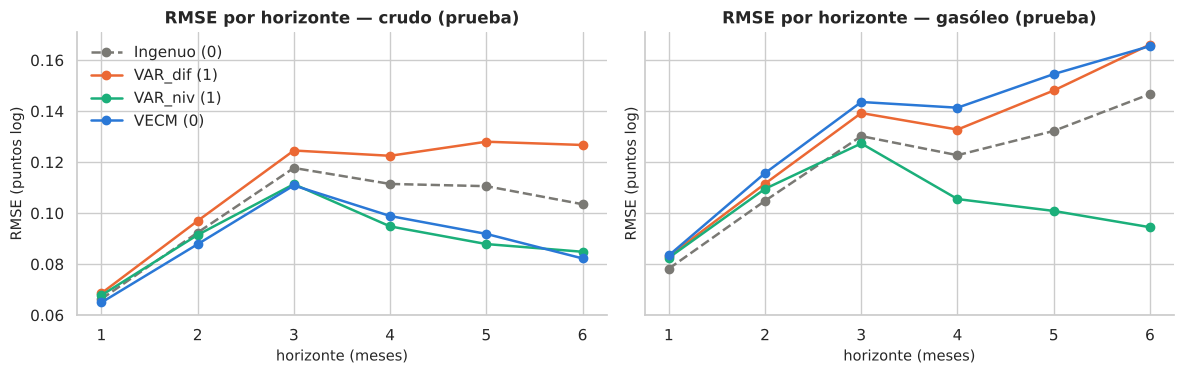

In [31]:
test = pd.concat([origen_movil(m, p, INI_TEST, FIN_TEST) for m, p in elegidos.items()], ignore_index=True)
rmse = lambda e: float(np.sqrt(np.mean(np.square(e))))

def tabla_metricas(df):
    t = df.groupby("modelo").agg(MAE_crudo=("e_CL", lambda e: e.abs().mean()), RMSE_crudo=("e_CL", rmse),
                                 MAE_gasoleo=("e_HO", lambda e: e.abs().mean()), RMSE_gasoleo=("e_HO", rmse),
                                 n=("e_CL", "size"))
    t["RMSE prom. / ingenuo"] = (t["RMSE_crudo"] + t["RMSE_gasoleo"]) / (t.loc["Ingenuo", "RMSE_crudo"] + t.loc["Ingenuo", "RMSE_gasoleo"])
    return t.sort_values("RMSE prom. / ingenuo")

print("Un paso (h = 1), puntos logarítmicos:")
display(tabla_metricas(test[test["h"] == 1]).round(4))
print("Varios pasos (h = 1 a 6 agrupados):")
display(tabla_metricas(test).round(4))

rmse_h = (test.assign(crudo=test["e_CL"] ** 2, gasoleo=test["e_HO"] ** 2)
              .groupby(["modelo", "h"])[["crudo", "gasoleo"]].mean().pipe(np.sqrt))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.9), sharey=True)
for ax, var, nombre in zip(axes, ["crudo", "gasoleo"], ["crudo", "gasóleo"]):
    for mod in elegidos:
        serie = rmse_h.loc[mod, var]
        ax.plot(serie.index, serie.values, marker="o", color=COL[mod], ls="--" if mod == "Ingenuo" else "-",
                label=f"{mod} ({elegidos[mod]})")
    ax.set_title(f"RMSE por horizonte — {nombre} (prueba)"); ax.set_xlabel("horizonte (meses)")
    ax.set_ylabel("RMSE (puntos log)")
axes[0].legend(loc="upper left")
plt.tight_layout(); plt.show()

### 10.3 Prueba de Diebold-Mariano

La prueba compara las pérdidas de dos modelos, $d_t = L(e^{A}_t) - L(e^{B}_t)$, con $H_0: E[d_t]=0$ (igual precisión).
Dos detalles importan:

- **Horizontes mayores que uno.** Los errores de pronósticos a $h$ pasos hechos en orígenes consecutivos se solapan, así que
  $d_t$ tiene autocorrelación hasta el orden $h-1$ aunque el modelo sea correcto. La varianza de $\bar d$ debe estimarse con
  esas autocovarianzas (estimador tipo Newey-West con $h-1$ rezagos), no con la varianza muestral simple.
- **Muestras pequeñas.** Harvey, Leybourne y Newbold (1997) proponen multiplicar el estadístico por
  $\sqrt{(n+1-2h+h(h-1)/n)/n}$ y compararlo con una $t$ de Student con $n-1$ grados de libertad.

Usamos la pérdida cuadrática promediada sobre las dos variables. Un estadístico positivo indica que el VECM tiene **mayor**
pérdida que el rival.

In [32]:
def diebold_mariano(perdida_a, perdida_b, h):
    # DM con varianza de largo plazo (autocovarianzas hasta h−1) y corrección de Harvey-Leybourne-Newbold
    d = np.asarray(perdida_a) - np.asarray(perdida_b)
    n, d_bar = len(d), d.mean()
    gammas = [np.mean((d[j:] - d_bar) * (d[:n - j] - d_bar)) for j in range(h)]
    var_d = (gammas[0] + 2 * sum(gammas[1:])) / n
    if var_d <= 0:                 # puede ocurrir en muestras muy pequeñas; se usa solo la varianza
        var_d = gammas[0] / n
    estad = d_bar / np.sqrt(var_d) * np.sqrt((n + 1 - 2 * h + h * (h - 1) / n) / n)
    return estad, 2 * stats.t.sf(abs(estad), n - 1), n

filas = []
for h in (1, 3, 6):
    sub = test[test["h"] == h].assign(l=lambda d: (d["e_CL"] ** 2 + d["e_HO"] ** 2) / 2)
    perd = sub.pivot(index="origen", columns="modelo", values="l").sort_index()
    for rival in ("Ingenuo", "VAR_dif", "VAR_niv"):
        est, p, n = diebold_mariano(perd["VECM"], perd[rival], h)
        filas.append({"h": h, "VECM frente a": rival, "DM (HLN)": est, "p-valor": p, "n": n,
                      "RMSE VECM": np.sqrt(perd["VECM"].mean()), f"RMSE rival": np.sqrt(perd[rival].mean())})
display(pd.DataFrame(filas).round(4))

,h,VECM frente a,DM (HLN),p-valor,n,RMSE VECM,RMSE rival
0,1,Ingenuo,2.0193,0.0595,18,0.0748,0.0725
1,1,VAR_dif,-0.6349,0.5339,18,0.0748,0.0762
2,1,VAR_niv,-0.1867,0.8541,18,0.0748,0.0755
3,3,Ingenuo,0.8802,0.3926,16,0.1283,0.1241
4,3,VAR_dif,-0.7526,0.4633,16,0.1283,0.1321
5,3,VAR_niv,0.6556,0.5220,16,0.1283,0.1196
6,6,Ingenuo,0.4136,0.6865,13,0.1307,0.1269
7,6,VAR_dif,-1.9810,0.0710,13,0.1307,0.1477
8,6,VAR_niv,1.5075,0.1575,13,0.1307,0.0898


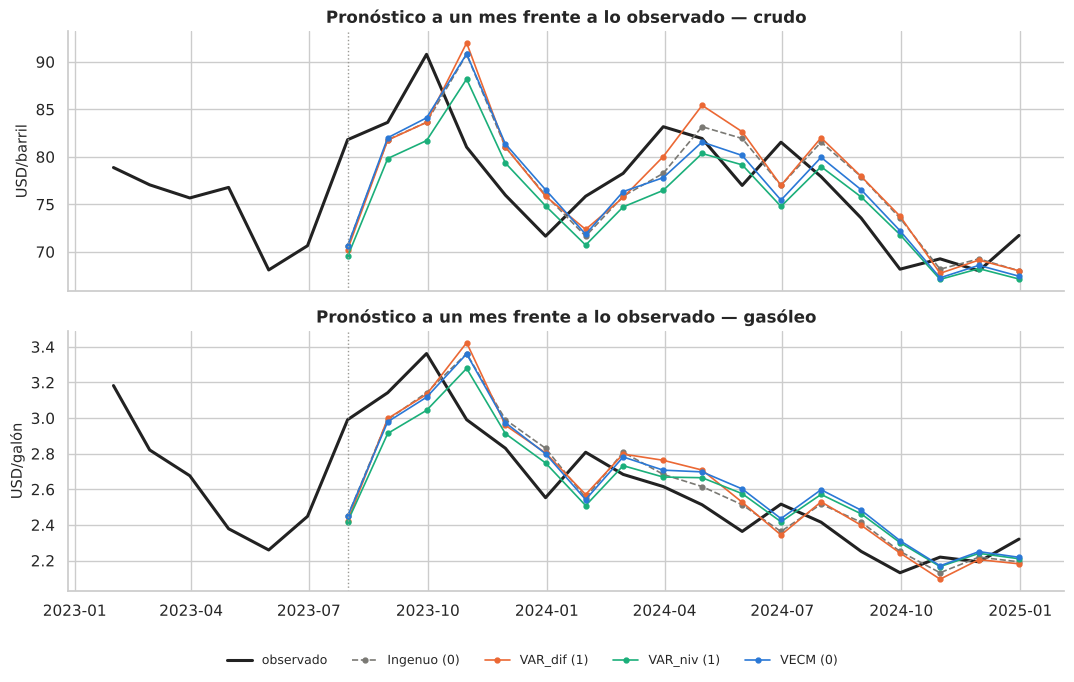

In [33]:
h1 = test[test["h"] == 1]
fig, axes = plt.subplots(2, 1, figsize=(11, 6.8), sharex=True)
for ax, (c, pc, nombre, unidad) in zip(axes, [("ln_CL", "pred_CL", "crudo", "USD/barril"), ("ln_HO", "pred_HO", "gasóleo", "USD/galón")]):
    obs = np.exp(datos.loc[INI_TEST - pd.DateOffset(months=6):, c])
    ax.plot(obs.index, obs, color=COL["obs"], lw=2.2, label="observado")
    for mod in elegidos:
        d = h1[h1["modelo"] == mod]
        ax.plot(d["objetivo"], np.exp(d[pc]), color=COL[mod], marker="o", ms=3.5, lw=1.2,
                ls="--" if mod == "Ingenuo" else "-", label=f"{mod} ({elegidos[mod]})")
    ax.axvline(INI_TEST, color=COL["ref"], ls=":", lw=1)
    ax.set_ylabel(unidad); ax.set_title(f"Pronóstico a un mes frente a lo observado — {nombre}")
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
manejadores, etiquetas = axes[0].get_legend_handles_labels()
fig.legend(manejadores, etiquetas, ncol=5, loc="lower center", fontsize=9, bbox_to_anchor=(0.5, -0.01))
plt.tight_layout(rect=(0, 0.05, 1, 1)); plt.show()

**Interpretación.**

- **Un paso.** En la prueba, el VECM tiene un error a un mes algo mayor que el ingenuo y parecido al de los VAR. Por
  variable, el patrón se repite en todos los horizontes: para el **crudo** el VECM es ligeramente mejor que el ingenuo; para
  el **gasóleo** es peor.
- **Varios pasos.** Agrupando $h=1,\dots,6$, el VAR en niveles obtiene el menor error y el VECM queda ligeramente por encima del
  ingenuo. El error del VECM en el gasóleo crece con el horizonte.
- **¿Son diferencias reales?** Ninguna comparación de Diebold-Mariano es significativa al 5 % en $h=1$, $3$ o $6$. Con 13 a 18
  pronósticos, la potencia es muy baja: **no podemos afirmar que ningún modelo sea superior**, y menos con base en
  diferencias de unas centésimas en el RMSE.
- **¿Por qué falla el VECM con el gasóleo?** Durante 2024 el desequilibrio estimado se mantuvo positivo (crudo "caro"
  relativo al gasóleo) casi todo el año, algo poco compatible con una semivida de 1.4 meses. El VECM esperaba que el gasóleo
  subiera para cerrar la brecha; en cambio siguió bajando, a medida que el margen de los destilados se normalizaba tras los
  máximos de 2022. Es la misma inestabilidad que sugerían las estimaciones recursivas.
- **Validación frente a prueba.** El VECM fue el mejor en validación y no en prueba. Con muestras de evaluación cortas,
  las clasificaciones son inestables.

**Lección.** Un VECM puede ser la representación econométricamente adecuada y la más interpretable y, aun así, no ser el
mejor pronosticador. Para precios de materias primas, cercanos a un paseo aleatorio, superar al modelo ingenuo es difícil.

### 10.4 Pronóstico de 2025 con el modelo final (ilustrativo, no evaluado)

Los intervalos de `predict` suponen errores gaussianos, supuesto que el diagnóstico rechazó: son orientativos y
probablemente demasiado estrechos en episodios extremos.

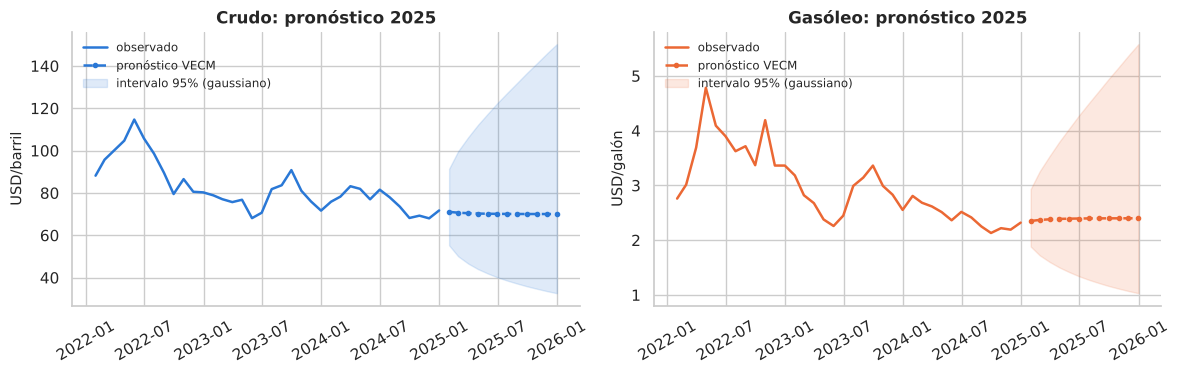

ln_CL                      ln_HO                
           pronóstico inf 95% sup 95% pronóstico inf 95% sup 95%
2025-01-31      71.06   55.25   91.40       2.35    1.88    2.93
2025-03-31      70.42   46.65  106.29       2.38    1.60    3.54
2025-06-30      70.12   40.13  122.51       2.40    1.34    4.28
2025-12-31      70.03   32.63  150.31       2.40    1.03    5.58

In [34]:
H_FUT = 12
pred, inf95, sup95 = vecm_res.predict(steps=H_FUT, alpha=0.05)
idx_fut = pd.date_range(datos.index[-1] + pd.offsets.MonthEnd(1), periods=H_FUT, freq="ME")
pron = {c: pd.DataFrame({"pronóstico": np.exp(pred[:, j]), "inf 95%": np.exp(inf95[:, j]), "sup 95%": np.exp(sup95[:, j])},
                        index=idx_fut) for j, c in enumerate(cols)}

fig, axes = plt.subplots(1, 2, figsize=(12, 3.9))
for ax, c in zip(axes, cols):
    color = COL[c[-2:]]
    hist = mensual.iloc[-36:, cols.index(c)]
    ax.plot(hist.index, hist, color=color, label="observado")
    ax.plot(idx_fut, pron[c]["pronóstico"], color=color, ls="--", marker="o", ms=3, label="pronóstico VECM")
    ax.fill_between(idx_fut, pron[c]["inf 95%"], pron[c]["sup 95%"], color=color, alpha=0.15, label="intervalo 95% (gaussiano)")
    ax.set_title(f"{corto[c].capitalize()}: pronóstico 2025"); ax.legend(loc="upper left", fontsize=8.5)
    ax.set_ylabel("USD/barril" if "CL" in c else "USD/galón")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m")); ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()
display(pd.concat(pron, axis=1).iloc[[0, 2, 5, 11]].round(2))

**Interpretación.** Con constante restringida, el modelo no tiene deriva: el pronóstico central se mueve solo para cerrar
el desequilibrio de diciembre de 2024 (sube el gasóleo y baja levemente el crudo) y luego se estabiliza. El intervalo se
ensancha con el horizonte, como corresponde a series $I(1)$. Nada en este gráfico se ha contrastado con datos de 2025.

> **Actividad 10.1 (después de comparar pronósticos).** ¿El modelo más complejo ofrece necesariamente mejores
> pronósticos? Argumente con los resultados de la validación, de la prueba y de Diebold-Mariano. ¿Qué tendría que ocurrir
> para que usted recomendara el VECM como herramienta de pronóstico?

---
## Módulo 11. Conclusiones y limitaciones

**¿Existe una relación estable de largo plazo?** Sí, con matices. Ambas series se comportan como $I(1)$ (evidencia
coherente con constante; no concluyente con tendencia). Con la especificación determinista coherente con los datos
(constante restringida, sin deriva) la prueba de Johansen encuentra exactamente una relación de cointegración con 0 a 3
rezagos. La relación estimada, $\ln CL\approx 3.51 + 0.845\ln HO$, es estable entre especificaciones; la homogeneidad
estricta se rechaza con la muestra completa pero no con la previa a 2022.

**¿Qué variable ajusta?** En la especificación principal, el gasóleo; no se rechaza la exogeneidad débil del crudo. Esta
conclusión **no es robusta** a los rezagos. Lo robusto es que el sistema corrige ($\beta'\alpha<0$) y lo hace en pocos meses.

**¿Qué ocurre ante un choque?** Con Cholesky (crudo primero), un choque al crudo tiene efectos permanentes y
significativos sobre ambos precios y se transmite al gasóleo en pocos meses; los choques propios del gasóleo son en gran
parte transitorios. Las magnitudes dependen del orden de identificación.

**¿Pronostica mejor?** No de forma demostrable: en la prueba fuera de muestra ningún modelo se distingue
estadísticamente de los demás, y el VECM no supera al paseo aleatorio en promedio. Su valor aquí es sobre todo **interpretativo**.

**Limitaciones.**

1. Muestra corta ($T=120$) con choques extremos (2020, 2022); residuos no normales y con ARCH.
2. Futuros continuos con posibles efectos de empalme (febrero de 2015).
3. Sistema bivariado: omite inventarios, márgenes, demanda y otros refinados, cuya inclusión podría cambiar $\beta$ y $\alpha$.
4. Las IRF dependen de una identificación recursiva; sus bandas *bootstrap* no corrigen sesgo ni heterocedasticidad.
5. Las pruebas de cambio estructural usan fechas fijadas de antemano; no se probó un quiebre de fecha desconocida.
6. Cointegración describe un vínculo estadístico de largo plazo; **no identifica relaciones causales**. La correlación
   describe co-movimiento (y puede ser espuria, Módulo 2); la cointegración afirma que una combinación es estacionaria; la
   causalidad exige un argumento de identificación adicional.

---
## Módulo 12. Actividades integradoras

1. Repita el análisis con `k_ar_diff = 2` (AIC). Compare $\hat\beta$, $\hat\alpha$ y la semivida simulada con las del modelo
   principal. ¿Qué conclusiones se mantienen?
2. Reestime el modelo con la muestra 2015-2019. ¿Sigue habiendo una relación de cointegración? ¿Cambia quién ajusta?
3. Reordene las columnas (`datos[["ln_HO", "ln_CL"]]`), reestime el VECM y escriba la nueva relación de largo plazo.
   Muestre que es la misma relación con otra normalización y explique los nuevos signos de $\alpha$.
4. Use `johansen(datos, 0, "co")` con los valores críticos simulados del caso 3 sin deriva (función `distribucion_nula`
   con `caso="co"`) y compare la decisión sobre $r$ con la del Módulo 6.
5. Calcule la FEVD con el orden gasóleo → crudo y compárela con la del Módulo 9.
6. Cambie el período de prueba a 2022-01 – 2023-06 (y la validación a un período anterior). ¿Se mantiene la clasificación
   de los modelos? ¿Qué dice eso sobre comparar modelos con 18 meses?
7. Un informe afirma: "el gasóleo corrige el 25 % del desequilibrio cada mes y el crudo causa al gasóleo". Señale cada error
   de interpretación usando los resultados de este cuaderno.

**Proyecto final.** Elija otro par (o trío) de series con un argumento económico de equilibrio y desarrolle el análisis
completo reutilizando las funciones de este cuaderno. Opciones: crudo WTI (`CL=F`) y Brent (`BZ=F`); crudo y gasolina RBOB
(`RB=F`); crudo, gasóleo y gasolina (sistema de tres variables); precio de la gasolina en surtidor y precio mayorista en EE. UU.
(cuaderno `16_VECM_Gasolina_Traslado_Precios.ipynb`). El entregable debe incluir: pregunta económica, datos congelados,
orden de integración, rezagos y Johansen con la especificación determinista justificada, interpretación de $\beta$, $\alpha$,
$\Gamma$ y ECT, diagnóstico, IRF con bandas, validación temporal con modelo ingenuo y conclusiones que distingan
asociación, cointegración y causalidad.

In [35]:
# Espacio para las actividades

---
## Respuestas sugeridas

Las respuestas se refieren a los resultados que produce el archivo de datos congelado.

**Actividad 1.1.** La serie del gasóleo se separaría de la del crudo a partir de ese año y no volvería. Si el cambio del margen
es permanente, la combinación lineal que era estacionaria tendría un cambio de nivel: con una relación de constante fija, en
toda la muestra el desequilibrio dejaría de ser estacionario y la prueba podría no detectar cointegración. Se podría recuperar
con un escalón en la relación (Módulo 8.3).

**Actividad 2.1.** Con 0.98 el error de equilibrio es muy persistente: se aleja del cero durante largos tramos y la prueba
de Engle-Granger probablemente no rechace la nula con $T=300$. En teoría las series siguen cointegradas (0.98 < 1), pero la
prueba tiene poca potencia para distinguir un proceso tan persistente de uno con raíz unitaria.

**Actividad 2.2.** La varianza muestral de un paseo aleatorio crece con $T$; dos series con varianzas grandes y tendencias
locales comparten tramos de subida y bajada por azar, y la regresión los "ajusta". El $R^2$ no converge a cero, sino a una
variable aleatoria, y el estadístico $t$ crece con $\sqrt T$ (Phillips, 1986).

**Actividad 3.1.** Corrige la variable 2: $\Delta y_{2t} = 0.10\,ECT_{t-1}$. La variable 1 es débilmente exógena respecto a $\beta$.
La brecha se reduce en $-\beta'\alpha = -(0 - 0.10) = 0.10$, es decir, un 10 % por período.

**Actividad 4.1.** El promedio mensual suaviza la serie e introduce autocorrelación artificial en las diferencias (el cambio
del promedio de un mes al siguiente comparte días con información común), lo que puede exigir más rezagos y alterar las
pruebas de raíz unitaria. El último cierre es una observación puntual del precio y evita ese efecto.

**Actividad 6.1.** Con dos precios $I(1)$ y un argumento de margen, se espera $r=1$. Encontrar $r=0$ haría dudar del
argumento económico (o de la especificación). Encontrar $r=2$ implicaría que ambas series son estacionarias, lo que
contradice las pruebas de raíz unitaria y haría dudar de ellas o de la especificación determinista de Johansen.

**Actividad 6.2.** Si ya hay una combinación estacionaria, queda una sola dirección no estacionaria (la tendencia común). La
prueba de $H_0: r\le 1$ pregunta si esa dirección también es estacionaria, es decir, si tiene raíz unitaria. Rechazarla
implicaría que ambas series son estacionarias, en contradicción con el Módulo 5.

**Actividad 7.1.** En niveles: $CL = e^{3.51}\,HO^{0.845}\approx 33.4\,HO^{0.845}$. Con $HO = 2.50$, $CL^{*}\approx 33.4\times 2.50^{0.845}\approx 72$
USD/barril (el cuaderno imprime la constante exacta para recalcularlo). No es un pronóstico porque es el valor de equilibrio
**dado** el gasóleo; el precio observado puede estar lejos de él, y el propio gasóleo también se moverá.

**Actividad 7.2.** Responde el gasóleo ($\hat\alpha_{HO}>0$, significativo). Que no se rechace la exogeneidad débil del crudo
significa que el crudo, cuyo precio se forma en un mercado global más amplio, no reacciona de forma detectable al margen de
refinación; el que se ajusta es el precio del producto. Si se normaliza sobre el gasóleo, el ECT cambia de signo (y escala), y
el $\alpha$ del gasóleo pasa a ser negativo.

**Actividad 7.3.** (1) Con dos rezagos el $\hat\alpha$ del gasóleo no es significativo, y es el crudo el que parece ajustar: la
frase depende de una especificación. (2) Un $\alpha$ individual no es el porcentaje de corrección del desequilibrio: la
corrección total depende de $\beta'\alpha$ y, con rezagos, también de $\Gamma$.

**Actividad 8.1.** Con autocorrelación residual, los estimadores y las distribuciones de los estadísticos de Johansen dejan de
ser válidos (los regresores rezagados se correlacionan con el error). La no normalidad afecta sobre todo la eficiencia y los
intervalos de pronóstico. $\hat\beta$ es superconsistente (converge a ritmo $T$), mientras que $\hat\alpha$ converge a ritmo
$\sqrt T$ y es más sensible a la muestra y a los rezagos.

**Actividad 9.1.** Impacto: el crudo sube ≈ 12.8 % y el gasóleo ≈ 9.2 %. Transición: el gasóleo sigue subiendo y el crudo
retrocede un poco durante 3-6 meses. Largo plazo: ≈ +10.5 % y ≈ +12.5 %, en la proporción que dicta $\beta$. Los efectos
sobre los niveles no vuelven a cero porque las series son $I(1)$: el choque se incorpora a la tendencia común. Lo que vuelve a
cero es el desequilibrio.

**Actividad 10.1.** No. En validación el VECM fue el mejor, en prueba no superó al ingenuo, y Diebold-Mariano no distingue
ningún par de modelos. Para recomendarlo como herramienta de pronóstico haría falta una ventaja consistente en varios
períodos de evaluación y diferencias significativas, idealmente a los horizontes relevantes para el usuario.

**Actividad 12.7.** (1) 25 % es un $\alpha$ individual, no la corrección total ($-\beta'\alpha\approx 38.5\,\%$ en el modelo
principal). (2) El ajuste del gasóleo no es robusto a los rezagos. (3) "Causa" confunde causalidad de Granger o el signo de
$\alpha$ con causalidad económica; además, las IRF dependen del orden de Cholesky.

---
## Apéndice A. Derivación del VECM a partir de un VAR(2)

Partimos de $\mathbf y_t = \mathbf c + \mathbf A_1\mathbf y_{t-1} + \mathbf A_2\mathbf y_{t-2} + \boldsymbol\varepsilon_t$. Restamos $\mathbf y_{t-1}$
y sumamos y restamos $\mathbf A_2\mathbf y_{t-1}$:

$$\Delta\mathbf y_t = \mathbf c + (\mathbf A_1 + \mathbf A_2 - \mathbf I)\,\mathbf y_{t-1} - \mathbf A_2(\mathbf y_{t-1}-\mathbf y_{t-2}) + \boldsymbol\varepsilon_t
= \mathbf c + \boldsymbol\Pi\,\mathbf y_{t-1} + \boldsymbol\Gamma_1\Delta\mathbf y_{t-1} + \boldsymbol\varepsilon_t,$$

con $\boldsymbol\Pi = \mathbf A_1 + \mathbf A_2 - \mathbf I$ y $\boldsymbol\Gamma_1 = -\mathbf A_2$. En general, para un VAR($p$):

$$\boldsymbol\Pi = -\Big(\mathbf I - \sum_{i=1}^{p}\mathbf A_i\Big),\qquad \boldsymbol\Gamma_i = -\sum_{j=i+1}^{p}\mathbf A_j,\quad i=1,\dots,p-1 .$$

Si las series son $I(1)$, $\Delta\mathbf y_t$ es estacionario, de modo que $\boldsymbol\Pi\mathbf y_{t-1}$ también debe serlo: o
$\boldsymbol\Pi=\mathbf 0$ (sin cointegración), o $\boldsymbol\Pi$ tiene rango reducido $r$ y $\boldsymbol\Pi=\boldsymbol\alpha\boldsymbol\beta'$ con
$\boldsymbol\beta'\mathbf y_{t-1}$ estacionario. `vecm_res.var_rep` devuelve las matrices $\mathbf A_i$ implícitas.

## Apéndice B. El procedimiento de Johansen

1. Regresar $\Delta\mathbf y_t$ sobre $\Delta\mathbf y_{t-1},\dots,\Delta\mathbf y_{t-p+1}$ (y la constante, en el caso 3) → residuos $\mathbf R_{0t}$.
2. Regresar $\mathbf y_{t-1}$ (aumentado con una columna de unos, en el caso 2) sobre los mismos regresores → residuos $\mathbf R_{1t}$.
3. Calcular $\mathbf S_{ij} = n^{-1}\sum_t \mathbf R_{it}\mathbf R_{jt}'$ y resolver $|\lambda\mathbf S_{11} - \mathbf S_{10}\mathbf S_{00}^{-1}\mathbf S_{01}| = 0$.
4. Los autovalores $\hat\lambda_i$ son correlaciones canónicas al cuadrado entre $\mathbf R_{0t}$ y $\mathbf R_{1t}$; los autovectores
   asociados a los $r$ mayores son las estimaciones de máxima verosimilitud de $\boldsymbol\beta$ (y de $\mu_0$ en el caso 2).
5. La verosimilitud maximizada con rango $r$ es, salvo constantes, $-\frac{n}{2}\sum_{i=1}^{r}\ln(1-\hat\lambda_i)$, de donde salen
   los estadísticos de traza y de máximo autovalor como razones de verosimilitud.

La función `johansen` del Módulo 6 implementa exactamente estos pasos.

---
## Referencias

- Dickey, D. A., & Fuller, W. A. (1979). Distribution of the estimators for autoregressive time series with a unit root.
  *Journal of the American Statistical Association, 74*(366), 427–431.
- Diebold, F. X., & Mariano, R. S. (1995). Comparing predictive accuracy. *Journal of Business & Economic Statistics, 13*(3), 253–263.
- Engle, R. F., & Granger, C. W. J. (1987). Co-integration and error correction: Representation, estimation, and testing.
  *Econometrica, 55*(2), 251–276.
- Granger, C. W. J., & Newbold, P. (1974). Spurious regressions in econometrics. *Journal of Econometrics, 2*(2), 111–120.
- Hamilton, J. D. (1994). *Time Series Analysis*. Princeton University Press.
- Harvey, D., Leybourne, S., & Newbold, P. (1997). Testing the equality of prediction mean squared errors. *International
  Journal of Forecasting, 13*(2), 281–291.
- Hyndman, R. J., & Athanasopoulos, G. (2021). *Forecasting: Principles and Practice* (3.ª ed.). OTexts. https://otexts.com/fpp3/
- Johansen, S. (1988). Statistical analysis of cointegration vectors. *Journal of Economic Dynamics and Control, 12*(2–3), 231–254.
- Johansen, S. (1991). Estimation and hypothesis testing of cointegration vectors in Gaussian vector autoregressive models.
  *Econometrica, 59*(6), 1551–1580.
- Johansen, S. (1995). *Likelihood-Based Inference in Cointegrated Vector Autoregressive Models*. Oxford University Press.
- Juselius, K. (2006). *The Cointegrated VAR Model: Methodology and Applications*. Oxford University Press.
- Kilian, L. (1998). Small-sample confidence intervals for impulse response functions. *Review of Economics and Statistics,
  80*(2), 218–230.
- Kwiatkowski, D., Phillips, P. C. B., Schmidt, P., & Shin, Y. (1992). Testing the null hypothesis of stationarity against
  the alternative of a unit root. *Journal of Econometrics, 54*(1–3), 159–178.
- Lütkepohl, H. (2005). *New Introduction to Multiple Time Series Analysis*. Springer.
- Newey, W. K., & West, K. D. (1987). A simple, positive semi-definite, heteroskedasticity and autocorrelation consistent
  covariance matrix. *Econometrica, 55*(3), 703–708.
- Nielsen, B., & Rahbek, A. (2000). Similarity issues in cointegration analysis. *Oxford Bulletin of Economics and
  Statistics, 62*(1), 5–22.
- Osterwald-Lenum, M. (1992). A note with quantiles of the asymptotic distribution of the maximum likelihood cointegration
  rank test statistics. *Oxford Bulletin of Economics and Statistics, 54*(3), 461–472.
- Phillips, P. C. B. (1986). Understanding spurious regressions in econometrics. *Journal of Econometrics, 33*(3), 311–340.
- Seabold, S., & Perktold, J. (2010). statsmodels: Econometric and statistical modeling with Python. *Proceedings of the 9th
  Python in Science Conference*, 92–96.
- Documentación de `statsmodels`: *Vector Error Correction Models (VECM)*,
  https://www.statsmodels.org/stable/vector_ar.html#vector-error-correction-models-vecm